# Cómo trabajo, paso a paso

**Los datos de este cuaderno son inventados.** La empresa, sus clientes, sus
productos y todas las cifras los construí yo, para poder mostrar el método
completo —con los defectos que traen los datos de verdad y con lo que no se
puede responder— sin usar información de nadie. No es trabajo hecho para un
cliente: es una demostración de cómo trabajo.

La empresa del ejercicio es una distribuidora de abarrotes y artículos de
limpieza en Zapopan, Jalisco: 38 empleados, dos bodegas, tres vendedores y doce
meses de operación, de octubre de 2025 a septiembre de 2026.

## Cómo está armado

Siete pasos, en el orden en que los hago cuando me llegan los datos de un negocio:

1. Lo que pedí y lo que llegó
2. Perfilado y validación contra los totales
3. Registro de defectos
4. Supuestos declarados
5. Hallazgos por dinero en juego
6. Lo que estos datos NO alcanzan a responder
7. Cómo sabremos si funcionó

En cada paso va **primero la explicación y después el código**, y cada renglón
de código trae a la derecha qué está haciendo. Los números salen de
`datos/recibido/`, que se reconstruye con `python3 generar_datos.py` y una
semilla fija: dos corridas dan exactamente lo mismo.

# Paso 1 · Lo que pedí y lo que llegó

Antes de tocar un número, la lista de lo que pedí y el cotejo contra lo que de
verdad llegó. Responde la primera pregunta que hace un dueño: **«¿qué me va a
pedir y voy a poder dárselo?»**.

Pedí seis archivos, los mismos que pido siempre. Lo que no exista se anota como
ausente: un dato que falta es un hallazgo, no un obstáculo.

In [1]:
# * ---- ARRANQUE DEL CUADERNO: LAS HERRAMIENTAS Y DÓNDE ESTÁN LOS DATOS ---
# * Esta celda no calcula nada. Prepara el terreno: trae las herramientas que se usan
# * en todo el cuaderno, decide cómo se van a ver las gráficas y las tablas, y
# * encuentra la carpeta donde están los archivos del cliente.

import csv
from datetime import date
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# * ---- PARTE 1 · LAS CINCO HERRAMIENTAS ---
# import csv → el lector de archivos CSV que ya viene con Python. Es el que abre
#   cada archivo del cliente y separa sus columnas por comas.
# from datetime import date → el tipo «date», que representa un día del calendario
#   (año, mes y día, sin hora). Sirve para comparar fechas y contar días entre ellas.
# from pathlib import Path → «Path», la forma moderna de manejar rutas de archivos:
#   una ruta deja de ser un texto y se vuelve un objeto que sabe unir carpetas,
#   listar su contenido y decir si algo existe, sin pegar diagonales a mano.
# import pandas as pd → pandas, la biblioteca de tablas. «as pd» es solo un apodo:
#   de aquí en adelante se escribe pd para no repetir el nombre largo.
# import matplotlib.pyplot as plt → la parte de matplotlib que dibuja. «as plt» es
#   otro apodo, el de siempre en la comunidad.
# ? Las cinco se importan juntas por legibilidad: quien abre el cuaderno ve de un
# ? golpe con qué herramientas está tratado el problema.

plt.rcParams["figure.figsize"] = (10, 4.5)
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.titleweight"] = "bold"
plt.rcParams["font.size"] = 11

# * ---- PARTE 2 · CÓMO SE VAN A VER LAS GRÁFICAS ---
# plt.rcParams es un diccionario de ajustes generales: lo que se guarda ahí aplica a
#   cada gráfica que se dibuje después, sin repetirlo en cada una. El texto entre
#   corchetes es el nombre del ajuste; lo de la derecha del igual, el valor que se le
#   pone.
# ["figure.figsize"] = (10, 4.5) → 10 pulgadas de ancho por 4.5 de alto: suficiente
#   para leerse en la pantalla de un teléfono sin hacer zoom.
# ["figure.dpi"] = 110 → resolución de la imagen. A 110 puntos por pulgada el texto
#   no sale borroso cuando GitHub la muestra.
# ["axes.grid"] = True → dibuja una rejilla de fondo, que ayuda a seguir un valor con
#   la vista hasta el eje.
# ["grid.alpha"] = 0.3 → deja la rejilla al 30 % de opacidad: se alcanza a ver, pero
#   no compite con la línea del dato.
# ["axes.titlesize"] = 13 → tamaño de letra del título de cada gráfica.
# ["axes.titleweight"] = "bold" → el título va en negritas.
# ["font.size"] = 11 → tamaño base de toda la letra de la gráfica.
# ? Se configuran aquí, al principio, aunque las primeras gráficas aparecen hasta el
# ? paso 5: así ninguna sale con el estilo de fábrica por descuido.

pd.set_option("display.max_colwidth", 70)
pd.set_option("display.width", 150)

# * ---- PARTE 3 · CÓMO SE VAN A VER LAS TABLAS ---
# pd.set_option también ajusta la presentación, pero de las tablas de pandas. El
#   primer valor es el nombre del ajuste y el segundo, su valor.
# ["display.max_colwidth"] = 70 → deja que una celda tenga hasta 70 caracteres antes
#   de cortarla con puntos suspensivos, para que el texto se lea completo.
# ["display.width"] = 150 → ancho de la tabla en caracteres; con esto las columnas ya
#   no se acomodan en dos renglones.

def carpeta_raiz() -> Path:
    """Sube desde la carpeta actual hasta encontrar datos/recibido."""
    for base in [Path.cwd(), *Path.cwd().parents]:
        if (base / "datos" / "recibido").is_dir():
            return base
    raise FileNotFoundError("No encuentro datos/recibido")

# * ---- PARTE 4 · LA FUNCIÓN QUE ENCUENTRA LA CARPETA ---
# def carpeta_raiz() -> Path: → define una función llamada carpeta_raiz. El «-> Path»
#   es una anotación: dice que lo que devuelve es una ruta. No cambia el
#   comportamiento, solo documenta.
# """Sube desde la carpeta actual hasta encontrar datos/recibido.""" → el docstring:
#   la frase que explica qué hace la función. Python la guarda como su descripción y
#   es lo primero que aparece al pedir ayuda sobre ella.
# for base in [Path.cwd(), *Path.cwd().parents]: → recorre una lista de carpetas, de
#   la actual hacia arriba. Path.cwd() es la carpeta de trabajo actual;
#   Path.cwd().parents es la cadena de carpetas que la contienen, y el asterisco (*)
#   la despliega dentro de la lista: el resultado es [la actual, su madre, su abuela,
#   y así hasta el disco].
# if (base / "datos" / "recibido").is_dir(): → la diagonal une carpetas cuando se
#   trabaja con Path: aquí arma la ruta «base/datos/recibido» y pregunta si es una
#   carpeta que existe (.is_dir()).
# return base → si existe, devuelve esa carpeta y la función termina ahí mismo.
# raise FileNotFoundError("No encuentro datos/recibido") → si la lista se acaba sin
#   encontrarla, lanza un error con ese mensaje.
# ! Es preferible un error claro a un cuaderno que sigue corriendo con datos vacíos:
# ! un análisis que empieza sin datos termina en conclusiones sin datos.

RAIZ = carpeta_raiz()
RUTA_DATOS = RAIZ / "datos" / "recibido"
archivos = sorted(RUTA_DATOS.iterdir())
print("Datos del cliente:", RUTA_DATOS.relative_to(RAIZ),
      "·", len(archivos), "archivos")

# * ---- PARTE 5 · PONER TODO EN MARCHA ---
# RAIZ = carpeta_raiz() → llama a la función y guarda lo que devuelve: la carpeta del
#   proyecto.
# RUTA_DATOS = RAIZ / "datos" / "recibido" → con esa raíz arma la ruta completa de
#   los archivos que mandó el cliente.
# archivos = sorted(RUTA_DATOS.iterdir()) → iterdir() lista todo lo que hay dentro
#   de la carpeta y sorted() lo ordena por nombre, para que el orden no cambie entre
#   una corrida y otra.
# print("Datos del cliente:", RUTA_DATOS.relative_to(RAIZ), "·", len(archivos), "archivos")
#   → muestra en pantalla la ruta relativa al proyecto (relative_to le quita la parte
#   de arriba, para no publicar la ruta de esta máquina) y cuántos archivos hay (len
#   cuenta los elementos de la lista). print acepta varias cosas separadas por comas
#   y las imprime en una sola línea.

def tabla(datos, dinero=(), parte=()):
    """Da formato de dinero y de porcentaje, y pinta en rojo lo negativo."""
    vista = datos.copy()
    for columna in dinero:
        vista[columna] = vista[columna].map(lambda x: f"{x:,.2f}")
    for columna in parte:
        vista[columna] = vista[columna].map(lambda x: f"{x:.1%}")
    con_color = vista.style.map(lambda v: "color: #A32020"
                                if isinstance(v, str) and v.startswith("-") else "")
    display({"text/html": con_color.to_html(), "text/plain": vista.to_string()},
            raw=True)

# * ---- EL AYUDANTE QUE DA FORMATO A LAS TABLAS ---
# def tabla(datos, dinero=(), parte=()) → recibe una tabla y los nombres de las columnas que
#   son dinero y de las que son porcentaje. Los dos últimos argumentos empiezan vacíos, así
#   que se pueden omitir cuando la tabla no tiene dinero.
# .map(lambda x: f"{x:,.2f}") → cambia cada número por un texto con separador de miles y dos
#   decimales. Es lo que hace que 19816680.09 se lea 19,816,680.09 y que la columna se pueda
#   comparar de un vistazo.
# .map(lambda x: f"{x:.1%}") → lo mismo para los porcentajes, que así dejan de ser 0.0929 y
#   pasan a 9.3 %.
# .style.map(...) → arma la tabla con un estilo: si el valor ya es texto y empieza con un
#   signo de menos, se pinta en rojo.
# display({...}, raw=True) → muestra la tabla en dos versiones al mismo tiempo: una de HTML,
#   que es la que lleva el color, y una de texto plano con los mismos números formateados.
#   Si el lector abre el cuaderno en un visor que no dibuja HTML —GitHub a veces recorta los
#   estilos—, igual ve la tabla con sus comas y sus signos. Y si solo se mostrara el HTML,
#   el respaldo de pandas sería la palabra «Styler» y una dirección de memoria, que no dice
#   nada.
# ? Se escribe una vez y se usa en todas las tablas del cuaderno: si mañana cambia el
# ? formato del dinero, cambia en un solo lugar y no en siete.

Datos del cliente: datos/recibido · 10 archivos


## Los seis archivos que pedí

Cada archivo con las columnas que no pueden faltar, escritas como se las pedí al
dueño, y al lado el nombre que esa columna tiene en su sistema. Comparar esto es
el primer trabajo del paso: **el nombre que yo pido casi nunca es el nombre que
el sistema tiene**, y esa traducción es la que se revisa después, columna por
columna, contra el archivo que llegó.

In [2]:
# * ---- LO QUE PEDÍ, ARCHIVO POR ARCHIVO Y COLUMNA POR COLUMNA ---
# * Esta celda no lee ningún archivo: es la lista de lo que se le pidió al dueño,
# * escrita como datos para poder compararla, después y de forma automática, contra lo
# * que llegó de verdad.

LO_QUE_PEDI = [
    {
        "pedido": "Ventas o transacciones",
        "para": "margen, mezcla y estacionalidad",
        "archivo": ["ventas_12_meses.csv"],
        "columnas": {
            "fecha": "fecha",
            "documento": "folio",
            "cliente": "cliente_codigo",
            "producto": "producto_codigo",
            "cantidad": "cantidad",
            "precio unitario": "precio_unitario",
            "importe": "importe",
            "costo unitario (opcional)": None,
            "almacén o bodega (si existe)": None,
        },
    },
    {
        "pedido": "Catálogo de productos",
        "para": "costo real y margen por producto",
        "archivo": ["productos.csv"],
        "columnas": {
            "código": "codigo",
            "nombre": "nombre",
            "costo actual": "costo_actual",
            "fecha del costo (opcional)": None,
        },
    },
    {
        "pedido": "Catálogo de clientes",
        "para": "segmentación y riesgo de concentración",
        "archivo": ["clientes.csv"],
        "columnas": {
            "código": "codigo",
            "nombre": "nombre",
            "tipo (mayoreo o menudeo)": "tipo",
            "ciudad": "ciudad",
            "fecha de alta": "fecha_alta",
            "condiciones de crédito": "credito_dias",
        },
    },
    {
        "pedido": "Facturas y cobranza",
        "para": "días de cobro y antigüedad de cartera",
        "archivo": ["facturas.csv", "pagos.csv"],
        "columnas": {
            "folio": "folio",
            "cliente": "cliente_codigo",
            "fecha de emisión": "fecha_emision",
            "fecha de vencimiento": "fecha_vencimiento",
            "importe": "importe_total",
            "pagos con fecha e importe": "fecha_pago",
        },
    },
    {
        "pedido": "Egresos o compras",
        "para": "flujo de efectivo contra proveedores",
        "archivo": ["compras_egresos.csv"],
        "columnas": {
            "fecha": "fecha",
            "proveedor": "proveedor",
            "categoría": "categoria",
            "importe": "importe",
        },
    },
    {
        "pedido": "Inventario",
        "para": "capital detenido",
        "archivo": ["inventario.csv"],
        "columnas": {
            "producto": "producto_codigo",
            "existencia": "existencia",
            "fecha de corte": "fecha_corte",
            "costo": "costo_unitario",
        },
    },
]

# * ---- PARTE 1 · LA LISTA DE LO QUE PEDÍ ---
# LO_QUE_PEDI = [ ... ] → una lista de Python. Los corchetes la abren y la cierran, y
#   las comas separan sus elementos. Aquí cada elemento es un diccionario: un bloque
#   entre llaves con pares «nombre: valor».
# ? Se escribe como datos y no como un párrafo por una razón práctica: la celda de
# ? abajo compara esta lista contra los archivos reales. Si estuviera en prosa, la
# ? comparación sería a mano y nadie podría revisarla.
#
# Cada diccionario tiene cuatro llaves:
# "pedido" → el nombre del archivo como se lo pedí al dueño, en su idioma.
# "para" → para qué sirve ese archivo, en una frase. Es lo que le explico al cliente
#   para que entienda por qué lo necesito.
# "archivo" → el nombre del archivo que sí llegó. Va entre corchetes porque es una
#   lista: casi siempre es uno solo, pero «Facturas y cobranza» llegó partido en dos,
#   facturas.csv y pagos.csv.
# "columnas" → otro diccionario, metido dentro del primero. Cada par de adentro es «lo
#   que pedí en el idioma del dueño» → «el nombre que esa columna tiene de verdad en
#   su archivo». Ese diccionario interno es el corazón de la celda.
#
# Lo que agrupa las cosas son las llaves y los corchetes, no la sangría: la sangría
#   está puesta para que se lea, no para que funcione.
#
# Traducir es todo el trabajo de esta parte. Dos ejemplos claros:
# "fecha": "fecha" → pedí una columna llamada fecha y el archivo la llama igual.
# "documento": "folio" → pedí «documento» y el sistema la llama «folio»: la misma cosa
#   con otro nombre.
# Las traducciones que no son obvias:
# "condiciones de crédito": "credito_dias" → los días de crédito que le dio a ese
#   cliente: 30, 60 o 90.
# "tipo (mayoreo o menudeo)": "tipo" → cómo compra ese cliente.
# "importe": "importe_total" → en el catálogo de facturas, el importe se llama así.
# "pagos con fecha e importe": "fecha_pago" → esa columna no está en facturas.csv,
#   está en pagos.csv. La celda siguiente busca en los dos archivos.
#
# None es el «no hay nada» de Python, su equivalente a vacío. Aquí marca lo que pedí y
#   no llegó: en ventas son dos columnas, «costo unitario (opcional)» y «almacén o
#   bodega (si existe)»; en productos es una, «fecha del costo (opcional)».
# ! Ninguno de esos tres huecos se rellena a mano: se reportan como faltantes. Un dato
# ! que no existe y se rellena contamina todo lo que venga después.

filas_pedido = []
for p in LO_QUE_PEDI:
    llegaron = [c for c, real in p["columnas"].items() if real is not None]
    faltan = [c for c, real in p["columnas"].items() if real is None]
    filas_pedido.append({
        "Lo que pedí": p["pedido"],
        "Para qué": p["para"],
        "Archivo(s)": " + ".join(p["archivo"]),
        "Columnas": len(p["columnas"]),
        "No llegaron": ", ".join(faltan) if faltan else "ninguna",
    })

# * ---- PARTE 2 · CONTAR LO QUE LLEGÓ Y LO QUE FALTA ---
# filas_pedido = [] → una lista vacía, para ir guardando un renglón por cada archivo
#   pedido. Los corchetes sin nada adentro son una lista con cero elementos.
# for p in LO_QUE_PEDI: → recorre la lista de arriba. En cada vuelta, p es uno de los
#   diccionarios. p es solo un nombre corto que elegí; pude llamarlo archivo.
# llegaron = [c for c, real in p["columnas"].items() if real is not None]
#   Es una «comprensión de lista»: una forma de armar una lista en una sola línea. Se
#   lee de adentro hacia afuera:
#   · p["columnas"] es el diccionario interno de este archivo.
#   · .items() lo entrega como pares: (nombre que pedí, nombre que tiene el archivo).
#   · for c, real in ... toma cada par y lo separa en dos variables: c es el nombre que
#     yo pedí y real el que trae el archivo.
#   · if real is not None deja pasar solo los pares que sí tienen nombre real; los que
#     valen None son los que no llegaron.
#   · [c ...] dice que de cada par que pasa se guarde solo c: el nombre que pedí.
#   El resultado es la lista de columnas que sí llegaron.
# is not None, y no «!= None» → is pregunta por identidad, que es la forma correcta de
#   preguntar si algo es None.
# faltan = [...] → exactamente lo mismo, del otro lado: las que se quedaron vacías.
# filas_pedido.append({ ... }) → agrega un diccionario al final de la lista. Cada
#   diccionario que se agrega será un renglón de la tabla y cada llave, una columna.
# "Lo que pedí": p["pedido"] → toma el valor de esa llave en el diccionario de este
#   archivo.
# "Archivo(s)": " + ".join(p["archivo"]) → join pega en un solo texto los elementos de
#   una lista, usando lo que está entre comillas como pegamento. Aquí el pegamento es
#   « + », así que dos archivos quedan como «facturas.csv + pagos.csv».
# "Columnas": len(p["columnas"]) → cuántas columnas pedí para ese archivo.
# "No llegaron": ", ".join(faltan) if faltan else "ninguna" → si la lista de faltantes
#   tiene elementos, los pega separados por coma; si está vacía, escribe «ninguna». Es
#   la forma corta de un if/else: «X if condición else Y».

pedido = pd.DataFrame(filas_pedido)
pedido

# * ---- PARTE 3 · CONVERTIRLO EN TABLA ---
# pd.DataFrame(filas_pedido) → convierte la lista de diccionarios en una tabla de
#   pandas. Cada diccionario se vuelve un renglón y cada llave el nombre de una
#   columna; pandas alinea las llaves aunque en un diccionario vengan en otro orden.
# pedido → el notebook muestra el valor de la última expresión de la celda. Poner el
#   nombre de la variable, sin print, es la forma de ver la tabla con formato de tabla;
#   con print saldría como texto plano, apretado y difícil de leer.
# ? La tabla no se guarda en ningún archivo: vive en memoria mientras el cuaderno corre
# ? y se vuelve a construir cada vez que se ejecuta.

,Lo que pedí,Para qué,Archivo(s),Columnas,No llegaron
0,Ventas o transacciones,"margen, mezcla y estacionalidad",ventas_12_meses.csv,9,"costo unitario (opcional), almacén o bodega (si existe)"
1,Catálogo de productos,costo real y margen por producto,productos.csv,4,fecha del costo (opcional)
2,Catálogo de clientes,segmentación y riesgo de concentración,clientes.csv,6,ninguna
3,Facturas y cobranza,días de cobro y antigüedad de cartera,facturas.csv + pagos.csv,6,ninguna
4,Egresos o compras,flujo de efectivo contra proveedores,compras_egresos.csv,4,ninguna
5,Inventario,capital detenido,inventario.csv,4,ninguna


## Lo que llegó

El inventario de la carpeta, sin interpretarlo todavía: cuántos archivos hay,
cuántas filas y cuántas columnas trae cada uno. Y después la carta con la que el
dueño mandó todo, en sus palabras, porque él mismo explica ahí lo que no pudo
sacar y por qué. Esa carta es evidencia, no adorno.

In [3]:
# * ---- INVENTARIO DE LA CARPETA: QUÉ HAY Y DE QUÉ TAMAÑO ---
# * Esta celda no interpreta nada todavía: solo abre cada archivo, cuenta sus renglones
# * y sus columnas, y arma una tabla con el inventario de lo que mandó el dueño.

llego = []
for ruta in archivos:
    if ruta.suffix != ".csv":
        llego.append({"Archivo": ruta.name,
                      "Filas": None,
                      "Columnas": None,
                      "Qué trae": "la carta del dueño, en texto"})
        continue
    with ruta.open(encoding="utf-8-sig") as f:
        encabezado = next(csv.reader(f))
        renglones = sum(1 for _ in f)
    llego.append({"Archivo": ruta.name,
                  "Filas": renglones,
                  "Columnas": len(encabezado),
                  "Qué trae": ", ".join(encabezado[:4]) +
                              ("…" if len(encabezado) > 4 else "")})

# * ---- PARTE 1 · RECORRER LA CARPETA ---
# llego = [] → otra lista vacía que va a acumular un diccionario por archivo. El nombre
#   se escribe sin acento a propósito: Python acepta acentos en nombres de variables,
#   pero la convención es evitarlos y así no hay sorpresas al teclear.
# for ruta in archivos: → archivos es la lista que se armó en la celda de arranque con
#   sorted(RUTA_DATOS.iterdir()). En cada vuelta, ruta es un objeto Path, no un texto.
# if ruta.suffix != ".csv": → .suffix devuelve la extensión del archivo, con todo y
#   punto (".csv", ".txt"). El != significa «distinto de».
# llego.append({ ... }) → el único archivo que no es una tabla es la carta del dueño.
#   Se agrega al inventario con Filas y Columnas en None, porque no aplican.
# continue → salta lo que queda de esta vuelta y pasa al siguiente archivo. Sin esto,
#   el código de abajo intentaría leer un .txt como si fuera una tabla.
# with ruta.open(encoding="utf-8-sig") as f: → abre el archivo y lo cierra solo al
#   terminar el bloque, aunque algo falle en medio. El encoding es la codificación de
#   los acentos: utf-8-sig además ignora una marca invisible que Excel pone al
#   principio del archivo. f es el archivo abierto.
# encabezado = next(csv.reader(f)) → csv.reader es el lector: entrega el archivo
#   renglón por renglón, ya separado en columnas. next() toma el primero de esos
#   renglones, que es el encabezado, y lo deja como una lista de nombres.
# renglones = sum(1 for _ in f) → el archivo quedó abierto en el segundo renglón, así
#   que esto cuenta los renglones que faltan: por cada renglón que entrega, suma 1.
# ? Por qué sum(1 for _ in f) y no len(f): f no es una lista, es un flujo que se va
# ? consumiendo renglón por renglón; no tiene un tamaño que se pueda preguntar.
#   El guion bajo es la convención para decir «este valor no me interesa»: aquí solo
#   importa cuántos hay, no cuáles son.
# ", ".join(encabezado[:4]) → los corchetes con dos puntos son un rebanado: [:4] toma
#   los primeros cuatro elementos de la lista. join los pega con coma y espacio.
# ("…" if len(encabezado) > 4 else "") → si hay más de cuatro columnas, agrega puntos
#   suspensivos; si no, agrega un texto vacío. El + pega ese pedazo al texto de antes.

llegaron = pd.DataFrame(llego)
llegaron["Filas"] = llegaron["Filas"].astype("Int64")
llegaron["Columnas"] = llegaron["Columnas"].astype("Int64")
llegaron

# * ---- PARTE 2 · LA TABLA DEL INVENTARIO ---
# pd.DataFrame(llego) → la misma conversión de la celda anterior: lista de
#   diccionarios a tabla, un renglón por diccionario.
# llegaron["Filas"].astype("Int64") → la columna tiene números y una celda vacía (la
#   de la carta), y pandas la vuelve decimal para poder convivir con el hueco. astype
#   fuerza el tipo: «Int64» con I mayúscula es el entero de pandas que sí admite vacío.
#   Sin esto, el 180 se vería como 180.0.
# llegaron → la última expresión de la celda es la que se muestra.

,Archivo,Filas,Columnas,Qué trae
0,clientes.csv,180,8,"codigo, nombre, rfc, tipo…"
1,compras_egresos.csv,60,4,"fecha, proveedor, categoria, importe"
2,facturas.csv,514,5,"folio, cliente_codigo, fecha_emision, fecha_vencimiento…"
3,inventario.csv,120,5,"producto_codigo, producto_nombre, existencia, fecha_corte…"
4,nota_del_cliente.txt,<NA>,<NA>,"la carta del dueño, en texto"
5,notas_credito.csv,181,9,"folio_nota, fecha_nota, cliente_codigo, folio_factura…"
6,pagos.csv,363,5,"folio_pago, fecha_pago, cliente_codigo, factura_aplicada…"
7,productos.csv,120,6,"codigo, nombre, categoria, unidad…"
8,reporte_mensual_ventas.csv,12,3,"mes, ventas_netas_con_iva, ventas_netas_sin_iva"
9,ventas_12_meses.csv,5339,12,"fecha, folio, lote_carga, cliente_codigo…"


In [4]:
print((RUTA_DATOS / "nota_del_cliente.txt").read_text(encoding="utf-8"))

# * ---- LA CARTA DEL DUEÑO, TAL CUAL LA ESCRIBIÓ ---
# (RUTA_DATOS / "nota_del_cliente.txt") → arma la ruta completa de la carta con la
#   misma diagonal de Path que ya se usó para unir carpetas.
# .read_text(encoding="utf-8") → lee todo el archivo de texto de un jalón y lo
#   devuelve como un solo texto. El encoding es el de los acentos.
# print(...) → lo muestra en pantalla.
# ? Se imprime el archivo en lugar de copiar su contenido al cuaderno por una razón:
# ? así lo que se lee es siempre lo que el dueño mandó. Si se copiara, el cuaderno y
# ? la carta podrían decir cosas distintas y nadie lo notaría.

Asunto: lo que alcancé a mandarle

Buen día. Le mando lo que pude sacar del sistema. Le explico lo que sí y lo
que no, para que no se confíe.

VENTAS. Le mandé el reporte de ventas de los doce meses, de octubre del año
pasado a septiembre de este. Ojo: el reporte lo saca mi contador y luego yo lo
vuelvo a bajar para mandárselo, así que puede venir algo desacomodado.

FACTURAS Y PAGOS. De aquí solo le puedo dar los últimos seis meses, de abril a
septiembre. El sistema viejo se reinstaló en marzo y para atrás ya no me da el
reporte de facturas. El de ventas sí me lo da porque lo tengo en Excel.

NOTAS DE CRÉDITO. Van aparte, en su archivo. Son las devoluciones que nos
regresan las tiendas. Yo esas las cargo al mes en que me las regresan, no al
mes en que se facturaron, porque así me lo pide el contador.

INVENTARIO. Le mando el corte del 30 de junio. No tengo uno más nuevo; el
almacenista lo levanta cada trimestre y el siguiente me toca hasta octubre.

PRODUCTOS. El costo que le mando es

## El cotejo

Aquí se cruzan las dos listas: qué pedí contra qué llegó, archivo por archivo y
columna por columna. La cuenta de «Llegaron» es sobre las columnas pedidas, y lo
que falta se escribe con su nombre, no en abstracto.

In [5]:
# * ---- EL COTEJO: QUÉ SE PIDIÓ CONTRA QUÉ LLEGÓ, COLUMNA POR COLUMNA ---
# * Aquí se cruzan la lista de lo que pedí con los archivos que existen en la carpeta.
# * Es la celda que convierte «creo que llegó todo» en un número que se puede revisar.

revision = []
for p in LO_QUE_PEDI:
    presentes, ausentes = [], []
    for nombre, real in p["columnas"].items():
        if real is None:
            ausentes.append(nombre)
            continue
        for archivo in p["archivo"]:
            with (RUTA_DATOS / archivo).open(encoding="utf-8-sig") as f:
                columnas = next(csv.reader(f))
            if real in columnas:
                presentes.append(nombre)
                break
        else:
            ausentes.append(nombre)
    revision.append({
        "Lo que pedí": p["pedido"],
        "Archivo que llegó": " + ".join(p["archivo"]),
        "Llegaron": f"{len(presentes)} de {len(p['columnas'])}",
        "Lo que falta": ", ".join(ausentes) if ausentes else "nada",
        "Estado": "completo" if not ausentes else "incompleto",
    })

# * ---- PARTE 1 · RECORRER CADA PEDIDO Y CADA COLUMNA ---
# revision = [] → la lista que va a acumular un renglón por archivo pedido.
# presentes, ausentes = [], [] → dos listas en una sola línea. Python asigna el primer
#   valor al primer nombre y el segundo al segundo; aquí cada uno recibe una lista
#   vacía. Se reinician en cada vuelta del ciclo, para no arrastrar lo del archivo
#   anterior.
# for nombre, real in p["columnas"].items(): → el mismo patrón de antes: .items()
#   entrega pares (lo que pedí, lo que trae el archivo) y se separan en dos nombres.
# if real is None: → si esa columna no llegó, se anota y se salta a la siguiente. No
#   hay nada que buscar en los archivos.
# for archivo in p["archivo"]: → busca la columna en cada archivo del pedido: casi
#   siempre es uno, pero facturas y pagos son dos.
# with ... as f: columnas = next(csv.reader(f)) → se abre el archivo y se lee su
#   encabezado, igual que en la celda del inventario.
# if real in columnas: → la palabra in pregunta si un elemento está dentro de una
#   lista, y responde True o False.
# presentes.append(nombre) y break → si está, se anota y se corta el ciclo de
#   archivos con break: ya no hace falta buscar en el segundo.
# else: → y aquí la trampa. Este else no pertenece al if de arriba: pertenece al for.
#   Se ejecuta solo si el ciclo terminó sin break, o sea, si la columna no apareció en
#   ninguno de los archivos del pedido.
# ! Ese for/else es lo que más confunde de Python y por eso está aquí a la vista: un
# ! else alineado con el for no significa «si no», significa «si nunca se cortó».

# * ---- PARTE 2 · ARMAR EL RENGLÓN ---
# f"{len(presentes)} de {len(p['columnas'])}" → esto es un f-string: el texto empieza
#   con f y todo lo que va entre llaves se reemplaza por su valor. Aquí arma «7 de 9».
#   Dentro de las llaves hay comillas simples porque el texto de afuera usa dobles.
# "Lo que falta": ", ".join(ausentes) if ausentes else "nada" → si la lista tiene
#   algo, se pega separada por comas; si está vacía, se escribe «nada».
# "Estado": "completo" if not ausentes else "incompleto" → not invierte: si la lista
#   está vacía (no hay faltantes), el estado es «completo».

cotejo = pd.DataFrame(revision)
cotejo

# * ---- PARTE 3 · LA TABLA ---
# pd.DataFrame(revision) → lista de diccionarios a tabla, como las dos veces
#   anteriores: una llave por columna, un diccionario por renglón.
# cotejo → la última expresión de la celda es la que se muestra.

,Lo que pedí,Archivo que llegó,Llegaron,Lo que falta,Estado
0,Ventas o transacciones,ventas_12_meses.csv,7 de 9,"costo unitario (opcional), almacén o bodega (si existe)",incompleto
1,Catálogo de productos,productos.csv,3 de 4,fecha del costo (opcional),incompleto
2,Catálogo de clientes,clientes.csv,6 de 6,nada,completo
3,Facturas y cobranza,facturas.csv + pagos.csv,6 de 6,nada,completo
4,Egresos o compras,compras_egresos.csv,4 de 4,nada,completo
5,Inventario,inventario.csv,4 de 4,nada,completo


## La cobertura en el tiempo

Que un archivo llegue no quiere decir que cubra lo mismo que los otros. Aquí se
comparan los periodos: si el reporte del dueño trae doce meses y las facturas
solo una parte, hay preguntas de cobranza que no se van a poder contestar hacia
atrás, y eso se dice ahora y no al final del trabajo.

Para las fechas de venta se usa el reporte mensual del dueño y no el archivo de
ventas, porque ese archivo trae las fechas escritas como texto: cómo se leen
esas fechas es justamente el trabajo del paso 2.

In [6]:
# * ---- LA COBERTURA EN EL TIEMPO: QUÉ PERIODO CUBRE CADA COSA ---
# * Un archivo puede llegar completo y aun así no servir para una pregunta, si cubre
# * menos tiempo que los demás. Esta celda mide eso y lo deja en una tabla.

reporte = pd.read_csv(RUTA_DATOS / "reporte_mensual_ventas.csv")
facturas = pd.read_csv(RUTA_DATOS / "facturas.csv")
pagos = pd.read_csv(RUTA_DATOS / "pagos.csv")
compras = pd.read_csv(RUTA_DATOS / "compras_egresos.csv")
inventario = pd.read_csv(RUTA_DATOS / "inventario.csv")

# * ---- PARTE 1 · ABRIR LAS CINCO TABLAS QUE FALTAN ---
# pd.read_csv(ruta) → lee un archivo CSV y lo devuelve como tabla de pandas: un
#   renglón del archivo se vuelve un renglón de la tabla y el encabezado, los nombres
#   de las columnas. La ruta se arma con la diagonal de Path, igual que antes.
# ? Son cinco tablas y no una porque el dueño las manda separadas. Cada una tiene su
# ? propia granularidad: facturas y pagos van por documento, compras por mes y
# ? proveedor, el inventario por producto.

meses_venta = sorted(reporte["mes"].unique())
primer_mes, ultimo_mes = meses_venta[0], meses_venta[-1]
cierre = pd.Timestamp(ultimo_mes) + pd.offsets.MonthEnd(0)
corte_inventario = pd.to_datetime(inventario["fecha_corte"]).max()
corte_texto = corte_inventario.strftime("%Y-%m-%d")
atraso = (cierre - corte_inventario).days
meses = lambda s: len({f[:7] for f in s.astype(str)})
faltan_f = len(meses_venta) - meses(facturas["fecha_emision"])
faltan_p = len(meses_venta) - meses(pagos["fecha_pago"])

# * ---- PARTE 2 · MEDIR LOS PERIODOS ---
# reporte["mes"] → selecciona una columna: los corchetes con el nombre entre comillas.
#   El resultado es una columna suelta, no una tabla.
# .unique() → devuelve cada valor distinto una sola vez.
# sorted(...) → los ordena alfabéticamente. Aquí eso funciona de casualidad a favor:
#   como los meses están escritos «2025-10», el orden alfabético es el orden en el
#   tiempo.
# meses_venta[0] y meses_venta[-1] → el primero y el último de la lista. Los índices
#   negativos cuentan desde el final: -1 es el último elemento.
# pd.Timestamp(ultimo_mes) → convierte el texto «2026-09» en una fecha que pandas
#   puede manejar. Ese texto vale por el día 1 del mes.
# + pd.offsets.MonthEnd(0) → lo lleva al último día de ese mismo mes: del 1 de
#   septiembre al 30 de septiembre. El 0 quiere decir «no cambies de mes, solo ve a su
#   final».
# pd.to_datetime(...) → convierte una columna de texto a fechas. .max() se queda con
#   la más reciente.
# .strftime("%Y-%m-%d") → pasa la fecha a texto con formato año-mes-día, para que se
#   lea igual que las demás fechas del cuaderno.
# (cierre - corte_inventario).days → restar dos fechas da una diferencia de tiempo, y
#   .days la expresa en días enteros.
# meses = lambda s: len({f[:7] for f in s.astype(str)}) → una función corta sin
#   nombre. Recibe una columna y devuelve cuántos meses distintos tiene. Por dentro:
#   .astype(str) asegura que todo sea texto, f[:7] corta cada fecha a sus primeros
#   siete caracteres (2026-04-15 queda como 2026-04, o sea, el mes), y las llaves {...}
#   arman un conjunto: como una lista, pero que no repite valores. Contar el conjunto
#   es contar meses distintos.
# faltan_f y faltan_p → cuántos meses de la ventana no alcanzan a cubrir las facturas
#   y los pagos.

cobertura = pd.DataFrame([
    {"Qué": "Reporte de ventas del dueño", "Desde": primer_mes,
     "Hasta": ultimo_mes, "Meses": len(meses_venta),
     "Contra la ventana": "completa: es la referencia"},
    {"Qué": "Ventas línea por línea", "Desde": primer_mes,
     "Hasta": ultimo_mes, "Meses": len(meses_venta),
     "Contra la ventana": "completa, pero con la fecha como texto"},
    {"Qué": "Facturas (cartera)", "Desde": facturas["fecha_emision"].min(),
     "Hasta": facturas["fecha_emision"].max(),
     "Meses": meses(facturas["fecha_emision"]),
     "Contra la ventana": f"le faltan {faltan_f} meses"},
    {"Qué": "Pagos (cobranza)", "Desde": pagos["fecha_pago"].min(),
     "Hasta": pagos["fecha_pago"].max(),
     "Meses": meses(pagos["fecha_pago"]),
     "Contra la ventana": f"le faltan {faltan_p} meses"},
    {"Qué": "Compras y egresos", "Desde": compras["fecha"].min(),
     "Hasta": compras["fecha"].max(), "Meses": meses(compras["fecha"]),
     "Contra la ventana": "completa"},
    {"Qué": "Inventario", "Desde": corte_texto,
     "Hasta": corte_texto, "Meses": 1,
     "Contra la ventana": f"{atraso} días antes del cierre"},
])

# * ---- PARTE 3 · LA TABLA ---
# Un diccionario por renglón, una llave por columna: el mismo patrón de las tablas
#   anteriores, ahora escrito de un jalón.
# .min() y .max() → la fecha más vieja y la más nueva de esa columna. Aquí sirven para
#   los extremos del periodo, no para promediar nada.
# f"le faltan {faltan_f} meses" → el f-string mete el número ya calculado dentro del
#   texto, para que la frase se arme sola y nunca quede desactualizada.
cobertura

# * cobertura → la última expresión de la celda: así se ve la tabla.

,Qué,Desde,Hasta,Meses,Contra la ventana
0,Reporte de ventas del dueño,2025-10,2026-09,12,completa: es la referencia
1,Ventas línea por línea,2025-10,2026-09,12,"completa, pero con la fecha como texto"
2,Facturas (cartera),2026-04-01,2026-09-29,6,le faltan 6 meses
3,Pagos (cobranza),2026-04-10,2026-09-30,6,le faltan 6 meses
4,Compras y egresos,2025-10-15,2026-09-15,12,completa
5,Inventario,2026-06-30,2026-06-30,1,92 días antes del cierre


## Lo que este paso deja

- **Nada faltó por completo y nada llegó completo.** Los seis archivos existen; las
  columnas que no llegaron están en la tabla del cotejo, con su nombre.
- Tres huecos ya cambian lo que se puede responder, y quedan declarados desde aquí:
  el archivo de ventas no trae el almacén, así que no se podrá separar por bodega;
  las facturas y los pagos no cubren la ventana completa, así que la antigüedad de
  cartera no se puede ver más atrás; y el inventario es de un solo corte viejo, así
  que no sirve para decir cuánto capital hay detenido hoy.
- El dueño mismo dice que no lleva costo por fecha y que no tiene estados de cuenta
  a la mano. Eso también se respeta: no se le pide lo que no tiene.

Con esto ya se puede empezar a trabajar. El **paso 2** perfila el archivo de ventas
y lo cuadra contra el total que el dueño reconoce en su reporte mensual: si esos dos
números no coinciden, no se avanza hasta saber por qué.

# Paso 2 · Perfilado y validación contra los totales

Aquí se abre el archivo de ventas y se cuenta lo que hay: cuántos registros, en qué
periodo, con qué granularidad, qué falta y qué se repite. Después se suma todo y se
compara contra el total que el dueño reconoce en su reporte mensual.

La regla que gobierna el paso es una sola: **si los dos totales no coinciden, no se
avanza**. Un análisis sobre datos que no cuadran no aguanta la primera pregunta del
contador, y esa pregunta llega siempre.

In [7]:
# * ---- ABRIR EL ARCHIVO DE VENTAS Y LOS DOS CATÁLOGOS ---
# * Empieza el paso 2 con la tabla más grande del cuaderno. Aquí solo se abre; lo que
# * dice y lo que le falta se revisa en las celdas siguientes.

RUTA_VENTAS = RUTA_DATOS / "ventas_12_meses.csv"
ventas = pd.read_csv(RUTA_VENTAS, dtype={"fecha": str})
productos = pd.read_csv(RUTA_DATOS / "productos.csv")
notas = pd.read_csv(RUTA_DATOS / "notas_credito.csv")
# `reporte`, `facturas` y `pagos` ya vienen cargados de la celda de cobertura.
COLUMNAS_ARCHIVO = list(ventas.columns)
nulos = ventas.isna().sum()
print(f"{len(ventas):,} filas · {len(COLUMNAS_ARCHIVO)} columnas")
ventas.head(4)

# * ---- PARTE 1 · LAS CUATRO TABLAS ---
# RUTA_VENTAS = ... → la ruta se guarda en una variable aparte para que la línea de
#   abajo no se alargue tanto.
# dtype={"fecha": str} → dtype fuerza el tipo con que pandas lee una columna. Aquí se
#   le pide que la fecha se lea como texto (str), porque el archivo la trae como texto
#   y pandas podría intentar adivinar y cambiar los valores.
# ? Se fuerza a texto a propósito: más adelante hay que leer esas fechas con reglas
# ? propias, y si pandas las convierte por su cuenta antes de tiempo, la conversión
# ? queda escondida y deja de poder revisarse.
# productos y notas → el catálogo y las devoluciones, con la misma función de siempre.
# COLUMNAS_ARCHIVO = list(ventas.columns) → .columns son los nombres de las columnas;
#   list() los vuelve una lista normal de Python para poder contarlos.
# nulos = ventas.isna().sum() → isna() marca cada celda: True si está vacía, False si
#   tiene algo. Al aplicar .sum() sobre esa tabla de True y False, cuenta los True de
#   cada columna. El resultado es una lista de números: cuántos vacíos tiene cada
#   columna.
# print(f"{len(ventas):,} filas · {len(COLUMNAS_ARCHIVO)} columnas") → el :, dentro de
#   las llaves es un formato: pone separador de miles, así 5339 se ve 5,339.
# ventas.head(4) → muestra los primeros cuatro renglones. Es la última expresión de la
#   celda, así que se muestra sola; head es «cabeza», el principio de la tabla.

5,339 filas · 12 columnas


,fecha,folio,lote_carga,cliente_codigo,cliente_nombre,producto_codigo,producto_nombre,cantidad,unidad,precio_unitario,importe,vendedor
0,2025-10-01,F-2025-10-0018,L-2025-10,C-0033,Fonda Las Flores,P-0001,Aceite vegetal Cerro Prieto 900 ml,60,botella,45.79,2747.40,V-01
1,2025-10-01,F-2025-10-0018,L-2025-10,C-0033,Fonda Las Flores,P-0016,Frijol negro Monte Alto 1 kg,151,bolsa,35.33,5334.83,V-01
2,2025-10-01,F-2025-10-0018,L-2025-10,C-0033,Fonda Las Flores,P-0057,Chocolate en polvo Doña Filo 800 g,26,caja,113.45,2949.70,V-01
3,2025-10-01,F-2025-10-0018,L-2025-10,C-0033,Fonda Las Flores,P-0067,Cereal de maíz Monte Alto 400 g,20,caja,66.86,1337.20,V-01


## Las fechas: cómo se leen antes de usarlas

La primera columna que hay que resolver es la fecha, porque sin ella no hay mes ni
estacionalidad. Viene como texto y en dos formatos mezclados, `dd/mm/aaaa` y
`mm/dd/aaaa`. La regla de lectura es esta: si uno de los dos primeros números pasa de
doce, ese número ya dice qué lugar ocupa y la fecha queda inequívoca; si los dos son
doce o menos, la fecha es ambigua y solo se resuelve con otra fuente.

Para esa otra fuente está el archivo de facturas del sistema, que trae la fecha de
emisión en formato ISO por folio. Cuando una línea es ambigua y su folio existe ahí,
se toma la fecha del sistema; cuando no existe, la línea se queda con la lectura
dominante y así se declara.

In [8]:
# * ---- LEER LAS FECHAS QUE VIENEN ESCRITAS COMO TEXTO ---
# * El archivo de ventas trae dos formatos mezclados, dd/mm y mm/dd. Esta celda los
# * separa, resuelve lo que se puede resolver con otra fuente y deja etiquetado lo que
# * no. Sin este paso no hay mes, ni estacionalidad, ni cuadre mensual.

FECHAS_FACTURA = dict(zip(facturas["folio"], facturas["fecha_emision"]))
# * ---- PARTE 1 · EL DICCIONARIO DE APOYO ---
# zip(a, b) → empareja dos columnas elemento por elemento: el primer folio con la
#   primera fecha, el segundo con la segunda, y así.
# dict(...) → convierte esos pares en un diccionario: folio → fecha. Después se puede
#   preguntar «¿cuál es la fecha de este folio?» en un solo paso, sin recorrer nada.

def leer_fecha(texto: str, folio: str) -> tuple[date, str]:
    """Devuelve la fecha de una línea y cómo se determinó."""
    if "-" in texto:
        return date.fromisoformat(texto), "ISO"
    a, b, anio = (int(p) for p in texto.split("/"))
    if a > 12:
        return date(anio, b, a), "dd/mm"
    if b > 12:
        return date(anio, a, b), "mm/dd"
    if folio in FECHAS_FACTURA:
        return date.fromisoformat(FECHAS_FACTURA[folio]), "cruzada"
    return date(anio, b, a), "ambigua sin contraparte"

# * ---- PARTE 2 · LA FUNCIÓN QUE LEE UNA FECHA ---
# def leer_fecha(texto: str, folio: str) -> tuple[date, str]: → recibe dos cosas y
#   devuelve una tupla de dos: una fecha y un texto. La anotación no cambia el
#   comportamiento, solo documenta qué entra y qué sale.
# """Devuelve la fecha...""" → el docstring, la frase que describe la función.
# if "-" in texto: → si el texto trae guiones viene en formato ISO (2026-04-01) y
#   date.fromisoformat lo convierte directo, sin ambigüedad posible.
# texto.split("/") → corta el texto por las diagonales y devuelve una lista de tres
#   partes: «05», «03» y «2026».
# (int(p) for p in ...) → convierte cada parte a número. a, b, anio = ... recibe las
#   tres en orden: a=5, b=3, anio=2026. Todavía no se sabe cuál es el día y cuál el
#   mes, y eso es justo el problema.
# if a > 12: → si el primer número pasa de doce no puede ser un mes, así que es el día
#   y la fecha se arma con (año, mes=b, día=a). Se devuelven dos cosas: la fecha y la
#   etiqueta de cómo se leyó, para poder contarlas después.
# if b > 12: → el caso espejo: el segundo número es el día, o sea, el texto venía en
#   mm/dd.
# if folio in FECHAS_FACTURA: → si ninguno de los dos pasa de doce, la fecha es
#   ambigua. Se busca el folio en el diccionario de apoyo; si está, se usa la fecha
#   del sistema.
# return date(anio, b, a), "ambigua sin contraparte" → si tampoco está ahí, se queda
#   con la lectura dd/mm, que es la dominante, y se etiqueta como ambigua.
# ! A una fecha ambigua no se le adivina el formato: o se resuelve con otra fuente, o
# ! se queda marcada. Un mes mal asignado mueve dinero de un mes a otro sin avisar.

pares = zip(ventas["fecha"], ventas["folio"])
lecturas = [leer_fecha(t, f) for t, f in pares]
ventas["fecha_real"] = [f for f, _ in lecturas]
ventas["como_lei"] = [c for _, c in lecturas]
mes = lambda f: f"{f.year}-{f.month:02d}"
ventas["mes"] = ventas["fecha_real"].map(mes)
ventas["como_lei"].value_counts().to_frame("líneas")

# * ---- PARTE 3 · APLICARLA A TODAS LAS LÍNEAS ---
# pares = zip(...) → otra vez zip, pero sin dict(): solo se van a recorrer los pares.
# lecturas = [leer_fecha(t, f) for t, f in pares] → comprensión de lista: llama a la
#   función una vez por par y guarda los resultados. Queda una lista de 5,339 pares
#   (fecha, etiqueta).
# ventas["fecha_real"] = [f for f, _ in lecturas] → los corchetes a la izquierda del
#   igual crean una columna nueva en la tabla. La comprensión toma el primer elemento
#   de cada par; el guion bajo descarta el segundo, que aquí no se necesita.
# ventas["como_lei"] = [c for _, c in lecturas] → la columna de las etiquetas: cómo se
#   leyó cada fecha.
# mes = lambda f: f"{f.year}-{f.month:02d}" → función corta: de una fecha saca
#   «2026-04». El :02d es formato: número entero de dos dígitos, con cero a la
#   izquierda si hace falta, para que enero sea 01 y no 1.
# .map(mes) → aplica esa función a cada elemento de la columna y devuelve la columna
#   transformada.
# .value_counts() → cuenta cuántas veces aparece cada valor. .to_frame("líneas") lo
#   convierte en tabla de una columna y le pone ese nombre. Es la última expresión, así
#   que se muestra.

,líneas
como_lei,
ISO,2569
dd/mm,1534
cruzada,866
mm/dd,192
ambigua sin contraparte,178


## El perfil del archivo

Con las fechas legibles, el retrato del archivo: volumen, periodo, granularidad,
columnas vacías y filas repetidas. La granularidad importa porque es la unidad de todo
lo que venga después: **una fila es una línea de documento, no una factura**; los
importes de una factura se suman al analizar cartera.

In [9]:
# * ---- EL PERFIL: EL RETRATO DEL ARCHIVO ---
# * Volumen, periodo, granularidad, vacíos y filas repetidas. Es lo que contestaría si
# * alguien pregunta «¿y qué trae tu archivo?» antes de ver un solo número de dinero.

LLAVE = ["fecha", "cliente_codigo", "producto_codigo",
         "cantidad", "precio_unitario", "importe"]
repetidas = ventas.duplicated(subset=LLAVE, keep="first")
con_nulos = int((nulos > 0).sum())
n_cols = len(COLUMNAS_ARCHIVO)
por_documento = len(ventas) / ventas.folio.nunique()

# * ---- PARTE 1 · DEFINIR QUÉ ES «LA MISMA FILA» ---
# LLAVE = [...] → las columnas que, juntas, identifican una línea de venta: mismo día,
#   mismo cliente, mismo producto, misma cantidad y mismo precio. Se escribe en
#   mayúsculas por convención: lo que no cambia durante el cuaderno va así.
# .duplicated(subset=LLAVE, keep="first") → recorre la tabla y marca con True las filas
#   que repiten una combinación de esas columnas. keep="first" deja la primera sin
#   marcar y marca las siguientes, para que la copia sea la que sobra.
# int((nulos > 0).sum()) → nulos > 0 compara cada número con cero y da True o False;
#   .sum() cuenta los True; int() lo deja como entero normal. El resultado es cuántas
#   columnas tienen al menos un vacío.
# ventas.folio.nunique() → cuántos folios distintos hay. ventas.folio es otra forma de
#   escribir ventas["folio"], válida cuando el nombre de la columna no tiene espacios.
# por_documento → líneas entre documentos: cuántas líneas tiene una factura en
#   promedio.

inicio = pd.Timestamp(primer_mes).date()
fin = cierre.date()
fuera = int(((ventas.fecha_real < inicio)
             | (ventas.fecha_real > fin)).sum())
dice = lambda k, v: {"Qué se mide": k, "Valor": v}

# * ---- PARTE 2 · ¿ALGUNA FECHA SE SALE DE LA VENTANA? ---
# .date() → de una fecha con hora saca solo el día, que es lo que interesa comparar.
# ventas.fecha_real < inicio → compara cada fecha con el primer día de la ventana y
#   devuelve True o False. Al hacerlo sobre una columna completa, el resultado es una
#   columna de True y False.
# | → la barra vertical es el «o» cuando se trabaja con esas columnas. En Python normal
#   sería la palabra or, que aquí no funciona.
# ! Los paréntesis alrededor de cada comparación son obligatorios: sin ellos, Python no
# ! sabe en qué orden evaluar y el resultado no es el que parece.
# .sum() → cuenta cuántos True quedaron: cuántas líneas caen antes del inicio o después
#   del cierre.
# dice = lambda k, v: {...} → una función de dos entradas que arma un diccionario de
#   dos llaves. Sirve para no escribir el mismo diccionario once veces abajo.

perfil = pd.DataFrame([
    dice("Líneas de venta", f"{len(ventas):,}"),
    dice("Documentos distintos", f"{ventas.folio.nunique():,}"),
    dice("Productos distintos", f"{ventas.producto_codigo.nunique():,}"),
    dice("Clientes distintos", f"{ventas.cliente_codigo.nunique():,}"),
    dice("Periodo leído en el archivo",
         f"{ventas.fecha_real.min()} a {ventas.fecha_real.max()}"),
    dice("Ventana que reconoce el dueño", f"{inicio} a {fin}"),
    dice("Líneas fuera de esa ventana", f"{fuera}"),
    dice("Granularidad", "una línea de documento"),
    dice("Columnas con nulos", f"{con_nulos} de {n_cols}"),
    dice("Filas repetidas exactas", f"{int(repetidas.sum()):,}"),
    dice("Líneas por documento", f"{por_documento:.2f}"),
])
perfil

# * ---- PARTE 3 · LA TABLA ---
# Cada llamada a dice(...) devuelve un diccionario de dos llaves, así que la lista de
#   once llamadas se convierte en una tabla de dos columnas: qué se mide y su valor.
# ? El periodo se muestra tal como sale de la lectura cruda, y por eso aparece más
# ? ancho que la ventana del dueño. No es un error de esta celda: son pocas líneas y la
# ? siguiente columna las cuenta. El paso 3 explica de dónde salen.
# perfil → última expresión de la celda: se muestra la tabla.

,Qué se mide,Valor
0,Líneas de venta,"5,339"
1,Documentos distintos,"1,148"
2,Productos distintos,120
3,Clientes distintos,157
4,Periodo leído en el archivo,2025-10-01 a 2026-12-06
5,Ventana que reconoce el dueño,2025-10-01 a 2026-09-30
6,Líneas fuera de esa ventana,7
7,Granularidad,una línea de documento
8,Columnas con nulos,0 de 12
9,Filas repetidas exactas,519


## El total del archivo contra el total del dueño

La prueba de fuego: sumar todo lo que trae el archivo y compararlo contra lo que el
dueño reconoce como su venta del periodo. Si coinciden, se sigue. Si no, la diferencia
hay que explicarla **completa**, no dejar un «más o menos».

In [10]:
# * ---- EL TOTAL DEL ARCHIVO CONTRA EL TOTAL DEL DUEÑO ---
# * La suma cruda de todo lo que trae el archivo, comparada contra el número que el
# * dueño reconoce como su venta. Aquí todavía no cuadra: eso es lo que hay que explicar.

bruto = round(ventas["importe"].sum(), 2)
del_dueno = round(reporte["ventas_netas_con_iva"].sum(), 2)
diferencia = round(bruto - del_dueno, 2)
print(f"Total del archivo ....... {bruto:>16,.2f}")
print(f"Total del dueño ......... {del_dueno:>16,.2f}")
print(f"Diferencia .............. {diferencia:>16,.2f}")
print(f"  sobre lo del dueño .... {diferencia / del_dueno:>16.1%}")

# * ---- PARTE 1 · LAS TRES CIFRAS ---
# .sum() → suma todos los valores de una columna. Aquí es la suma de la columna de
#   importes tal como viene en el archivo: sin quitar copias, sin corregir el IVA y sin
#   restar devoluciones.
# round(x, 2) → redondea a dos decimales, o sea, a centavos. Python guarda los números
#   decimales con pequeñas imprecisiones internas; redondear al final evita que salgan
#   colas como 41239939.170000002.
# del_dueno → la suma del reporte mensual del dueño. Es la referencia contra la que se
#   va a comparar todo.
# diferencia → la resta. Positiva quiere decir que el archivo dice más que el dueño.

# * ---- PARTE 2 · EL FORMATO DE LOS NÚMEROS ---
# {bruto:>16,.2f} → dentro de un f-string, lo que va después de los dos puntos es el
#   formato: > alinea a la derecha, 16 reserva dieciséis espacios, la coma pone
#   separador de miles y .2f deja dos decimales. Es lo que hace que las cifras queden
#   una debajo de otra y se puedan comparar con la vista.
# {diferencia / del_dueno:>16.1%} → la división da una proporción entre 0 y 1; el .1%
#   la muestra como porcentaje con un decimal, para leerla como «9 % de más».
# ? Este número no se presenta como un resultado: es la brecha que hay que cerrar, y
# ? en la celda de la conciliación se desarma pieza por pieza.

Total del archivo .......    41,239,939.17
Total del dueño .........    37,831,047.21
Diferencia ..............     3,408,891.96
  sobre lo del dueño ....             9.0%


## De dónde sale la diferencia

La diferencia no es un misterio ni un error de suma: es el resultado de tres cosas
técnicas que se pueden aislar una por una.

1. **Filas repetidas.** Hay líneas idénticas cargadas más de una vez, y sumarlas las
   cuenta dos veces. Se quitan por llave de negocio: mismo día, mismo cliente, mismo
   producto, misma cantidad y mismo precio. La primera se queda.
2. **Dos bases de IVA.** Una parte de los lotes de carga trae el precio sin IVA y el
   resto con IVA, así que la suma mezcla peras con manzanas. Se detectan comparando el
   precio de cada lote contra el precio de lista del catálogo: el lote que queda por
   debajo de lista viene sin IVA, y se le aplica la tasa. Que la tasa sea la correcta
   no se supone: se comprueba contra las notas de crédito, que traen las dos bases.
3. **Devoluciones sin restar.** Las notas de crédito vienen en su propio archivo y
   nunca se restaron de la venta. Se restan en el mes en que el dueño las carga, que es
   la convención que él mismo declara en su carta.

Las fechas no mueven el total, pero sí el mes en que cae cada peso: si una fecha se lee
al revés, el peso aparece en el mes equivocado y la estacionalidad se ve distinta.

In [11]:
# * ---- QUITAR LAS COPIAS Y HOMOGENEIZAR EL IVA ---
# * Las tres funciones de esta celda hacen el trabajo sucio del cuadre. Cada una recibe
# * una tabla y devuelve la tabla corregida junto con el monto que movió, para poder
# * explicar después de dónde salió cada peso.

IVA = 0.16

# * ---- PARTE 1 · LA TASA ---
# IVA = 0.16 → la tasa de IVA de México, 16 %, escrita como fracción porque así se usa
#   en las cuentas: precio × (1 + 0.16).
# ? La tasa no se da por buena: más abajo se comprueba contra las notas de crédito, que
# ? traen el mismo importe en las dos bases.

def quitar_repetidas(tabla: pd.DataFrame) -> tuple[pd.DataFrame, float]:
    """Deja una fila por línea y devuelve lo que quitó."""
    copias = tabla.duplicated(subset=LLAVE, keep="first")
    quitado = round(tabla.loc[copias, "importe"].sum(), 2)
    return tabla.loc[~copias].copy(), quitado

# * ---- PARTE 2 · QUITAR LAS FILAS REPETIDAS ---
# def quitar_repetidas(tabla) -> tuple[...]: → recibe una tabla y devuelve dos cosas:
#   la tabla limpia y un número. La anotación tuple[...] describe ese par; no cambia el
#   comportamiento.
# .duplicated(...) → la misma marca de copias de la celda del perfil: True en las filas
#   que repiten una línea que ya apareció.
# .loc[copias, "importe"] → .loc selecciona por filas y por columna al mismo tiempo,
#   en ese orden: [filas, columna]. Aquí, de las filas marcadas como copia, toma la
#   columna importe. Al sumarla se obtiene cuánto dinero están contando de más.
# ~copias → la tilde invierte el True y el False: lo que era «es copia» se vuelve «no
#   es copia». Así se queda uno con las filas buenas.
# .copy() → entrega una copia independiente de la tabla. Sin esto, la tabla nueva sería
#   la misma de antes y cualquier cambio afectaría a la original.
# return ... , quitado → devuelve dos valores separados por coma: la tabla y el monto.

def lotes_sin_iva(tabla: pd.DataFrame) -> list[str]:
    """Detecta los lotes cuyo precio viene por debajo del de lista."""
    con_lista = tabla.merge(productos[["codigo", "precio_lista_sin_iva"]],
                            left_on="producto_codigo", right_on="codigo")
    con_lista["razon"] = (con_lista["precio_unitario"]
                          / con_lista["precio_lista_sin_iva"])
    mediana = con_lista.groupby("lote_carga")["razon"].median()
    return sorted(mediana[mediana < 1.0].index)

# * ---- PARTE 3 · ENCONTRAR LOS LOTES QUE VINIERON SIN IVA ---
# tabla.merge(otra_tabla, left_on=..., right_on=...) → junta dos tablas por una columna
#   en común, como un buscarv: a cada renglón de ventas le pega el precio de lista del
#   producto. productos[[...]] toma solo esas dos columnas del catálogo; los corchetes
#   dobles significan «una lista de nombres de columna».
# con_lista["razon"] = precio / precio de lista → crea una columna con la división.
#   Si el resultado ronda 1, la venta se registró con IVA; si ronda 0.86, sin IVA.
# .groupby("lote_carga")["razon"].median() → agrupa las filas por lote y saca la
#   mediana de la razón de cada grupo. La mediana es el valor de en medio: no la
#   arrastran los casos raros, como sí pasa con el promedio.
# mediana[mediana < 1.0] → se queda solo con los lotes cuya mediana quedó por debajo
#   de 1, o sea, los que traen el precio sin IVA.
# .index → devuelve las etiquetas de esa selección: los nombres de los lotes. sorted
#   los ordena para que siempre salgan en el mismo orden.

def corregir_iva(tabla: pd.DataFrame, lotes: list) -> tuple:
    """Recalcula precio e importe de los lotes que venían sin IVA."""
    limpia = tabla.copy()
    es = limpia["lote_carga"].isin(lotes)
    nuevo = (limpia.loc[es, "precio_unitario"] * (1 + IVA)).round(2)
    limpia.loc[es, "precio_unitario"] = nuevo
    limpia["importe"] = (limpia["cantidad"] * limpia["precio_unitario"]).round(2)
    return limpia, round(limpia["importe"].sum() - tabla["importe"].sum(), 2)

# * ---- PARTE 4 · CORREGIR EL IVA ---
# limpia = tabla.copy() → se trabaja sobre una copia para no modificar la tabla
#   original: la suma cruda de la celda anterior tiene que seguir siendo la cruda.
# .isin(lotes) → True en las filas cuyo lote está dentro de la lista. Es la versión de
#   varios valores de lo que antes se hacía con ==.
# limpia.loc[es, "precio_unitario"] → las filas marcadas y, de ellas, la columna del
#   precio. Se multiplica por (1 + IVA), o sea por 1.16: el precio sin IVA más su 16 %.
#   .round(2) redondea toda la columna de una vez.
# limpia.loc[es, "precio_unitario"] = nuevo → escribe el resultado solo en las filas
#   marcadas. El resto de la tabla no se toca.
# limpia["importe"] = cantidad × precio → recalcula el importe de todas las filas con
#   el precio ya corregido, para que precio e importe no se contradigan.
# return limpia, ... → devuelve la tabla y cuánto sumó el ajuste: la diferencia entre
#   el total corregido y el original.

ventas_limpias, quitado = quitar_repetidas(ventas)
lotes = lotes_sin_iva(ventas_limpias)
ventas_limpias, ajuste_iva = corregir_iva(ventas_limpias, lotes)
tasa_notas = (notas["importe_con_iva"] / notas["importe_sin_iva"]).median()
print(f"Filas repetidas: {int(repetidas.sum()):,} · quitan {quitado:,.2f}")
print(f"Lotes sin IVA: {lotes} · suman {ajuste_iva:,.2f}")
print(f"IVA implícito en las notas: {tasa_notas:.4f}")

# * ---- PARTE 5 · PONERLAS EN ORDEN ---
# ventas_limpias, quitado = quitar_repetidas(ventas) → la función devuelve dos cosas y
#   aquí se reciben en dos variables, en el mismo orden en que salen.
# lotes = lotes_sin_iva(ventas_limpias) → la detección se hace sobre la tabla que ya
#   perdió las copias, no sobre la cruda.
# ventas_limpias, ajuste_iva = corregir_iva(ventas_limpias, lotes) → se corrige y el
#   resultado reemplaza a la variable anterior.
# ! El orden importa. Primero se quitan copias y después se corrige el IVA: si se
# ! hiciera al revés, las copias también se corregirían y el monto que se quita al
# ! deduplicar sería otro, con lo que la conciliación dejaría de cerrar.
# tasa_notas → el importe con IVA entre el importe sin IVA de cada nota. Si da 1.16, la
#   tasa del 16 % queda comprobada con los datos del cliente y no es un supuesto.
# Los tres print → dejan a la vista el monto de cada ajuste y la tasa comprobada, para
#   poder vigilarlos sin volver a correr nada.

Filas repetidas: 519 · quitan 3,387,556.19
Lotes sin IVA: ['L-2026-05', 'L-2026-06', 'L-2026-07'] · suman 1,429,268.70
IVA implícito en las notas: 1.1600


## La conciliación

De la suma cruda a la venta neta, peldaño por peldaño, para que cualquiera pueda
rehacer la resta. Y después el mismo cuadre mes a mes: un total anual que cierra puede
esconder dos meses que se compensan, y de esos nadie se entera hasta que la
estacionalidad no cuadra con lo que el dueño recuerda.

In [12]:
# * ---- LA CONCILIACIÓN: DE LA SUMA CRUDA A LA VENTA NETA ---
# * Se arma el puente completo, peldaño por peldaño, y se compara mes a mes contra el
# * reporte del dueño. Si algo no cerrara, aquí se vería en qué mes y por cuánto.

notas["mes"] = notas["fecha_nota"].astype(str).str[:7]
notas_total = round(notas["importe_con_iva"].sum(), 2)
homologado = round(bruto - quitado + ajuste_iva, 2)
mes_calculado = (ventas_limpias.groupby("mes")["importe"].sum()
                 .subtract(notas.groupby("mes")["importe_con_iva"].sum(),
                           fill_value=0).round(2))
neto_calculado = round(mes_calculado.sum(), 2)

# * ---- PARTE 1 · LAS PIEZAS DEL PUENTE ---
# notas["fecha_nota"].astype(str).str[:7] → el .str deja usar los métodos de texto
#   sobre una columna completa: [:7] corta cada fecha a sus primeros siete caracteres,
#   o sea, al mes. Así cada nota queda asignada al mes en que el dueño la cargó.
# notas_total → lo devuelto en todo el periodo.
# homologado → la venta bruta ya con copias fuera y con todo en la misma base de IVA.
# ventas_limpias.groupby("mes")["importe"].sum() → agrupa las ventas por mes y suma el
#   importe de cada grupo. El resultado es una serie con un valor por mes.
# .subtract(otra_serie, fill_value=0) → resta dos series alineándolas por su etiqueta,
#   que en este caso es el mes. fill_value=0 dice qué usar cuando un mes existe en una
#   y no en la otra: cero, en vez de dejar un hueco.
# .round(2) al final → se aplica sobre el resultado anterior: es un método encadenado,
#   cada punto trabaja sobre lo que dejó el anterior.
# neto_calculado → la suma de los doce meses ya restadas las notas.

conciliacion = pd.DataFrame([
    dice("Total tal como viene en el archivo", f"{bruto:,.2f}"),
    dice("Menos filas repetidas", f"{-quitado:,.2f}"),
    dice("Más el IVA que faltaba en tres lotes", f"{ajuste_iva:,.2f}"),
    dice("Venta bruta homologada", f"{homologado:,.2f}"),
    dice("Menos notas de crédito", f"{-notas_total:,.2f}"),
    dice("Venta neta calculada", f"{neto_calculado:,.2f}"),
    dice("Venta neta del reporte del dueño", f"{del_dueno:,.2f}"),
    dice("Diferencia", f"{round(neto_calculado - del_dueno, 2):,.2f}"),
])
conciliacion.set_index("Qué se mide").rename(columns={"Valor": "MXN"})

# * ---- PARTE 2 · LA TABLA DEL PUENTE ---
# Cada renglón es un paso: se parte del total del archivo y se le aplican los tres
#   ajustes en orden hasta llegar a la venta neta. Los montos que se restan van en
#   negativo para que la columna se pueda leer de arriba abajo.
# {-quitado:,.2f} → el signo de menos se escribe dentro del texto, sobre el número ya
#   calculado; el formato es el mismo de siempre.
# .set_index("Qué se mide") → usa esa columna como etiqueta de los renglones, en lugar
#   del 0, 1, 2 que pone pandas. Así la tabla se lee como una lista de conceptos.
# .rename(columns={"Valor": "MXN"}) → cambia el nombre de una columna, con un
#   diccionario de «nombre viejo: nombre nuevo».
# ? La última línea no se guarda en ninguna variable: se muestra tal cual, con los dos
# ? cambios aplicados, porque es la última expresión de la celda.

,MXN
Qué se mide,
Total tal como viene en el archivo,"41,239,939.17"
Menos filas repetidas,"-3,387,556.19"
Más el IVA que faltaba en tres lotes,"1,429,268.70"
Venta bruta homologada,"39,281,651.68"
Menos notas de crédito,"-1,450,604.47"
Venta neta calculada,"37,831,047.21"
Venta neta del reporte del dueño,"37,831,047.21"
Diferencia,0.00


In [13]:
# * ---- EL CUADRE MES A MES ---
# * Un total anual que cierra puede esconder dos meses que se compensan. Esta celda
# * compara los doce meses contra el reporte del dueño, uno por uno.

mensual = mes_calculado.to_frame("calculado")
mensual["del dueño"] = reporte.set_index("mes")["ventas_netas_con_iva"]
mensual = mensual.fillna(0)
mensual["diferencia"] = (mensual["calculado"] - mensual["del dueño"]).round(2)
mensual["calculado"] = mensual["calculado"].map(lambda x: f"{x:,.2f}")
mensual["del dueño"] = mensual["del dueño"].map(lambda x: f"{x:,.2f}")
mensual["diferencia"] = mensual["diferencia"].map(lambda x: f"{x:,.2f}")
mensual

# * ---- PARTE 1 · ARMAR LA COMPARACIÓN ---
# mes_calculado.to_frame("calculado") → una serie (una columna suelta) se vuelve tabla
#   de una columna; el argumento es el nombre que se le pone.
# reporte.set_index("mes")["ventas_netas_con_iva"] → se pone el mes como etiqueta de
#   los renglones y se toma la columna de la venta del dueño.
# ! Al asignar una serie a una columna, pandas la alinea por la etiqueta del renglón
# ! (el mes), no por el orden en que vengan. Por eso hay que poner el índice antes: si
# ! se asignara por posición, los meses se cruzarían y la tabla diría otra cosa.
# .fillna(0) → rellena los huecos con cero, para que un mes sin dato no deje la columna
#   a medias.
# mensual["diferencia"] = (...).round(2) → la resta de las dos columnas, redondeada a
#   centavos.

# * ---- PARTE 2 · DAR FORMATO ANTES DE MOSTRAR ---
# .map(lambda x: f"{x:,.2f}") → cambia cada número de la columna por un texto con
#   formato de dinero; x es cada valor por turno. Se hace al final para que las tres
#   columnas se vean iguales y se puedan comparar de un vistazo.
# mensual → la última expresión de la celda: se muestra la tabla.

,calculado,del dueño,diferencia
mes,,,
2025-10,"3,056,973.10","3,056,973.10",0.00
2025-11,"2,899,491.29","2,899,491.29",0.00
2025-12,"4,296,817.46","4,296,817.46",0.00
2026-01,"2,378,686.23","2,378,686.23",0.00
2026-02,"3,079,977.69","3,079,977.69",0.00
2026-03,"3,049,561.00","3,049,561.00",0.00
2026-04,"3,248,571.72","3,248,571.72",0.00
2026-05,"2,934,925.60","2,934,925.60",0.00
2026-06,"2,988,861.36","2,988,861.36",0.00


## Lo que este paso deja

- **El total cuadra, y cuadra mes por mes.** No quedó una diferencia «explicada a
  medias»: los doce meses cierran contra el número que el dueño reconoce.
- Los tres ajustes que movieron el total son técnicos, no de negocio: filas contadas
  dos veces, dos bases de IVA mezcladas y devoluciones que nunca se restaron. Ninguno
  cambia lo que la empresa vendió; cambian lo que el archivo decía que vendió.
- La tasa de IVA no se supuso: se comprobó contra las notas de crédito, que traen las
  dos bases por la misma devolución.
- Las fechas ambiguas se resolvieron cruzando el folio contra las facturas del sistema.
  Las que no tenían contraparte estaban en filas repetidas que se quitaron, no en la
  tabla limpia: por eso el perfil muestra un periodo más ancho que la ventana del
  dueño. El paso 3 las muestra una por una.

El archivo limpio (`ventas_limpias`) es el que se usa de aquí en adelante. El **paso 3**
se dedica a cada defecto por separado: qué se encontró, con qué evidencia, qué se
decidió y cuánto dinero mueve cada uno.

# Paso 3 · Registro de defectos

El cuadre del paso 2 dice que el total cierra. Eso no dice que los datos estén
limpios: cuatro de los ocho defectos no movieron ni un peso del total y aun así
cambian lo que se puede concluir. Este paso pone cada defecto en una fila, con cuatro
columnas fijas: **qué encontré, con qué evidencia, qué decidí y cuánto dinero mueve**.

La evidencia no es una impresión: es el conteo que se puede volver a hacer. Y el
efecto se mide, no se estima: cada cifra de la última columna sale de un cálculo que
está en esta misma celda o en las de arriba.

In [14]:
# * ---- DEFECTO 1 · FECHAS ESCRITAS COMO TEXTO, EN DOS FORMATOS ---
# * El efecto de este defecto no está en el total del año: está en el mes. Si una fecha
# * se lee al revés, el peso aparece en otro mes y la estacionalidad se ve distinta.

def mes_ingenuo(texto):
    """El mes que saldría leyendo todo como dd/mm, sin ninguna regla."""
    if "-" in texto:
        return texto[:7]
    a, b, anio = (int(p) for p in texto.split("/"))
    if b > 12:
        return None
    return f"{anio}-{b:02d}"

con_texto = int(ventas_limpias["fecha"].str.contains("/").sum())
ingenuo = ventas_limpias["fecha"].map(mes_ingenuo)
imposibles = int(ingenuo.isna().sum())
cambian = int((ingenuo.notna() & (ingenuo != ventas_limpias["mes"])).sum())
ok = ingenuo.notna()
malo = ventas_limpias[ok].groupby(ingenuo[ok])["importe"].sum()
bien = ventas_limpias[ok].groupby("mes")["importe"].sum()
desvio = malo.sub(bien, fill_value=0).round(2)
desvio_real = desvio.reindex(bien.index).fillna(0)
peor = desvio_real.abs().idxmax()
desvio_peor = float(desvio_real.loc[peor])
meses_tocados = int((desvio_real.abs() > 0.5).sum())
tabla(pd.DataFrame({"desvío": desvio.sort_values().head(3)}).rename_axis("mes"),
      dinero=["desvío"])

# * ---- PARTE 1 · QUÉ HABRÍA PASADO SIN LA REGLA ---
# mes_ingenuo(texto) → la función que simula al lector descuidado: parte la fecha por
#   las diagonales y supone que el primer número es el día, siempre.
# if "-" in texto: return texto[:7] → si la fecha ya viene en formato ISO, el mes son
#   sus primeros siete caracteres y no hay nada que suponer.
# if b > 12: return None → si el segundo número pasa de doce, la lectura dd/mm es
#   imposible (daría un mes 13 o mayor). Se devuelve None, que aquí quiere decir «esta
#   fecha no se puede leer así».
# ventas_limpias["fecha"].str.contains("/") → el .str deja usar métodos de texto sobre
#   toda la columna; contains("/") pregunta, renglón por renglón, si la fecha trae
#   diagonales, o sea, si está escrita como texto y no en ISO. El .sum() cuenta los
#   True: cuántas líneas están en ese caso.
# .map(mes_ingenuo) → aplica la función a cada fecha y devuelve una columna de meses
#   «ingenuos», con None donde la lectura es imposible.
# .isna() → marca con True las celdas vacías o None. Aquí cuenta las imposibles.
# (ingenuo.notna() & (ingenuo != ventas_limpias["mes"])) → dos condiciones unidas con
#   &: la fecha se pudo leer de las dos maneras y el mes no coincide. O sea, líneas que
#   la lectura descuidada habría puesto en otro mes.
# ok = ingenuo.notna() → la máscara de las que sí se pueden comparar. Se guarda para
#   usar exactamente las mismas líneas en los dos lados de la resta.
# groupby(ingenuo[ok])["importe"].sum() → suma el importe por mes según la lectura
#   descuidada; groupby("mes") hace lo mismo con el mes ya corregido.
# .sub(bien, fill_value=0) → resta los dos, tratando como cero el mes que aparece en una
#   lista y no en la otra. Un mes que solo existe en la lectura mala sale con su monto
#   completo: dinero que se habría inventado en un mes que no existe.
# .abs().idxmax() → abs convierte todo a positivo e idxmax devuelve la etiqueta del
#   mayor: el mes más afectado. .loc[peor] recupera su valor con signo.
# .reindex(bien.index).fillna(0) → restringe la comparación a los doce meses que existen
#   de verdad. Sin esto, un mes inventado por la lectura mala contaría como «mes
#   afectado», y la cifra diría más meses de los que hay.
# ? La última línea no calcula nada: muestra los tres meses más castigados, ordenados.
# ? Es la evidencia que el lector puede revisar sin confiar en el texto.

,desvío
mes,
2026-07,"-288,398.92"
2026-06,"-107,920.53"
2026-09,"-79,065.08"


In [15]:
# * ---- DEFECTOS 2 Y 3 · EL MISMO DINERO CONTADO DOS VECES ---
# * Los dos son filas repetidas, pero se cargaron distinto y se detectan distinto: uno
# * repite folios y el otro trae folios nuevos. Por eso van separados en el registro.

copias = ventas[repetidas]
reexportadas = copias[copias["lote_carga"].str.endswith("-RC")]
mes_doble = copias[copias["lote_carga"].str.endswith("-B")]
filas_rc = int(len(reexportadas))
monto_rc = round(float(reexportadas["importe"].sum()), 2)
folios_rc = int(reexportadas["folio"].nunique())
filas_b = int(len(mes_doble))
monto_b = round(float(mes_doble["importe"].sum()), 2)
print(f"reexportación: {filas_rc} filas en {folios_rc} folios · MXN {monto_rc:,.2f}")
print(f"mes duplicado: {filas_b} filas · MXN {monto_b:,.2f}")

# * ---- PARTE 1 · SEPARAR LAS DOS CLASES DE COPIA ---
# ventas[repetidas] → se queda solo con las filas que la marca del perfil señaló como
#   copia. repetidas es una columna de True y False del mismo largo que la tabla, así
#   que ponerla entre corchetes filtra los renglones.
# .str.endswith("-RC") → otro método de texto: pregunta si el lote termina con esas
#   letras. Es la forma de reconocer la reexportación de comprobantes.
# .str.endswith("-B") → y esta, la segunda carga del mismo mes. La diferencia entre las
#   dos importa: la reexportación repite folio, la segunda carga no; por eso la primera
#   se detecta por folio y la segunda por contenido.
# len(...) → cuántas filas. .nunique() en la columna de folios → cuántos documentos
#   distintos, que es la cifra que interesa: no 120 filas sueltas, sino 30 facturas
#   contadas dos veces.
# ? El monto de cada clase se mide sobre el archivo tal como llegó, con su precio sin
# ? corregir: es lo que el archivo decía de más, no lo que falta después de otras
# ? correcciones. Mezclar las dos cosas es como se hacen las conciliaciones que no cierran.

reexportación: 120 filas en 30 folios · MXN 660,993.04
mes duplicado: 399 filas · MXN 2,726,563.15


In [16]:
# * ---- DEFECTOS 4 Y 8 · DOS BASES DE IVA Y DEVOLUCIONES SIN RESTAR ---
# * Estos dos sí mueven el total, en direcciones opuestas, y quedaron corregidos en el
# * paso 2. Aquí solo se deja su evidencia, para que entre al registro con los demás.

lineas_iva = int(ventas_limpias["lote_carga"].isin(lotes).sum())
print(f"lotes sin IVA: {', '.join(lotes)}")
print(f"líneas afectadas: {lineas_iva:,} · ajuste: MXN {ajuste_iva:,.2f}")
print(f"notas de crédito: {len(notas):,} · MXN {notas_total:,.2f}")
print(f"tasa comprobada en las notas: {tasa_notas:.4f}")

# * ---- PARTE 1 · LA EVIDENCIA QUE YA ESTABA CALCULADA ---
# .isin(lotes) → True en las líneas cuyo lote está en la lista de los detectados; .sum()
#   las cuenta. Es el mismo criterio con el que se corrigió el IVA en el paso 2, no uno
#   nuevo inventado para esta tabla.
# ajuste_iva y notas_total vienen de las celdas anteriores: no se recalculan aquí, se
#   citan. Eso es lo que hace que la evidencia sea rastreable a la celda donde nació.
# tasa_notas → la tasa que se despeja de las propias notas. Cerrar el registro citándola
#   es lo que convierte «aplicamos 16 %» en «el 16 % está comprobado con tus datos».

lotes sin IVA: L-2026-05, L-2026-06, L-2026-07
líneas afectadas: 1,210 · ajuste: MXN 1,429,268.70
notas de crédito: 181 · MXN 1,450,604.47
tasa comprobada en las notas: 1.1600


In [17]:
# * ---- DEFECTOS 5 Y 6 · EL MISMO NEGOCIO DOS VECES Y EL MISMO PRODUCTO DOS NOMBRES ---
# * Ninguno de los dos toca el total. Los dos cambian una respuesta: quién es el cliente
# * más grande y qué producto es cuál. Se detectan buscando lo que se repite.

clientes = pd.read_csv(RUTA_DATOS / "clientes.csv")
rfc = clientes.set_index("codigo")["rfc"]
por_codigo = ventas_limpias.groupby("cliente_codigo")["importe"].sum()
por_rfc = ventas_limpias.assign(rfc=ventas_limpias["cliente_codigo"].map(rfc)) \
    .groupby("rfc")["importe"].sum()
total_venta = float(por_codigo.sum())
top3_codigo = float(por_codigo.nlargest(3).sum()) / total_venta
top3_rfc = float(por_rfc.nlargest(3).sum()) / total_venta
nombres_repetidos = clientes.groupby("nombre")["codigo"].nunique()
par = clientes[clientes["nombre"] == nombres_repetidos[nombres_repetidos > 1].index[0]]
cuentas = par["codigo"].tolist()
solo_una = float(por_codigo[cuentas[0]])
juntas = float(por_codigo[cuentas].sum())
lugar_juntas = int((por_codigo > juntas).sum()) + 1
nombres_producto = ventas_limpias.groupby("producto_codigo")["producto_nombre"].nunique()
renombrado = nombres_producto[nombres_producto > 1].index[0]
mitades = sorted(ventas_limpias[ventas_limpias["producto_codigo"] == renombrado]
                 ["producto_nombre"].unique())
u_nombre = ventas_limpias.groupby("producto_nombre")["cantidad"].sum().sort_values(ascending=False)
u_codigo = ventas_limpias.groupby("producto_codigo")["cantidad"].sum()
lugares = [list(u_nombre.index).index(n) + 1 for n in mitades]
lugar_codigo = int((u_codigo > u_codigo[renombrado]).sum()) + 1
parte_nueva = float(min(u_nombre[n] for n in mitades)) / float(u_codigo[renombrado])
print(f"el mismo negocio en dos cuentas: {cuentas}")
print(f"la mayor sola: MXN {solo_una:,.2f} · las dos juntas: MXN {juntas:,.2f} (lugar {lugar_juntas})")
print(f"concentración del top 3: {top3_codigo:.1%} por código · {top3_rfc:.1%} por RFC")
print(f"producto renombrado: {renombrado} · lugares por nombre {lugares} · por código {lugar_codigo}")
print(f"su volumen que parece nuevo: {parte_nueva:.1%}")

# * ---- PARTE 1 · EL CLIENTE QUE ES UNO Y SON DOS ---
# pd.read_csv(...) → el catálogo de clientes. Hasta ahora solo se habían contado sus
#   columnas; aquí se usa por primera vez para leer el RFC.
# .set_index("codigo")["rfc"] → convierte el catálogo en una lista que, dado un código
#   de cliente, devuelve su RFC. Es el diccionario de traducción que ya se usó con las
#   fechas, montado de otra forma.
# .assign(rfc=...) → agrega a la tabla de ventas una columna calculada al vuelo: el RFC
#   de cada cliente. .map(rfc) hace la traducción código por código.
# groupby("rfc") → agrupa por contribuyente y no por cuenta. Ahí es donde el negocio
#   con dos códigos se vuelve uno solo.
# .nlargest(3) → las tres columnas más grandes; .sum() las junta. Dividir entre el total
#   da la concentración, y la comparación entre las dos formas es el efecto del defecto.
# nombres_repetidos > 1 → los nombres que aparecen en más de un código. En lugar de
#   escribir a mano cuál es el cliente, se busca la condición: así la celda seguiría
#   funcionando si el par fuera otro.
# .tolist() → la columna de códigos como lista normal, para poder sumar las dos cuentas
#   en un solo paso: por_codigo[cuentas].sum().
# (por_codigo > juntas).sum() + 1 → cuántos clientes venden más que ese negocio
#   consolidado, más uno: su lugar en el ranking.
# * ---- PARTE 2 · EL PRODUCTO QUE CAMBIÓ DE NOMBRE ---
# .nunique() sobre el grupo de producto → cuántos nombres distintos tiene cada código.
#   El que tiene dos es el renombrado, y también se detecta por condición, no a mano.
# u_nombre y u_codigo → las mismas unidades agrupadas de las dos maneras: por el nombre
#   que aparece en el archivo y por el código del catálogo.
# list(u_nombre.index).index(n) + 1 → el lugar que ocupa un nombre en la lista ordenada
#   de mayor a menor, contando desde uno.
# parte_nueva → qué proporción de su volumen quedó en la mitad que nació en abril. Es
#   el tamaño del espejismo: parece un producto nuevo que apareció a mitad del año.

el mismo negocio en dos cuentas: ['C-0151', 'C-0180']
la mayor sola: MXN 2,141,510.65 · las dos juntas: MXN 3,503,719.71 (lugar 1)
concentración del top 3: 13.3% por código · 16.8% por RFC
producto renombrado: P-0110 · lugares por nombre [82, 97] · por código 55
su volumen que parece nuevo: 40.4%


In [18]:
# * ---- DEFECTO 7 · EL PAGO APLICADO A LA FACTURA EQUIVOCADA ---
# * Es el defecto más caro de leer mal, porque no cambia la cartera: cambia de qué
# * antigüedad es cada peso. Y la antigüedad es lo que dispara las decisiones de cobro.

emision = facturas.set_index("folio")["fecha_emision"]
vencimiento = pd.to_datetime(facturas.set_index("folio")["fecha_vencimiento"])
dias_atraso = (cierre.normalize() - vencimiento).dt.days

def tramo(dias):
    """Clasifica un atraso en el tramo de antigüedad que usa la cartera."""
    if dias <= 0:
        return "no vencido"
    if dias <= 30:
        return "1 a 30"
    if dias <= 60:
        return "31 a 60"
    if dias <= 90:
        return "61 a 90"
    return "más de 90"

def saldos(cobros):
    """Saldo por factura: lo facturado menos lo cobrado y menos lo devuelto."""
    s = facturas.set_index("folio")["importe_total"].astype(float)
    s = s.sub(cobros.groupby("factura_aplicada")["importe"].sum(), fill_value=0)
    s = s.sub(notas.groupby("folio_factura")["importe_con_iva"].sum(), fill_value=0)
    return s.round(2)

saldos_asis = saldos(pagos)
pagos_imposibles = pagos[pagos["fecha_pago"] < pagos["factura_aplicada"].map(emision)]
pagos_corregidos = pagos.copy()
for _, p in pagos_imposibles.iterrows():
    candidatas = facturas[(facturas["cliente_codigo"] == p["cliente_codigo"])
                          & (facturas["fecha_emision"] < p["fecha_pago"])]
    su_saldo = saldos_asis.reindex(candidatas["folio"])
    victima = su_saldo[(su_saldo - p["importe"]).abs() < 0.01]
    if len(victima) == 1:
        pagos_corregidos.loc[pagos_corregidos["folio_pago"] == p["folio_pago"],
                             "factura_aplicada"] = victima.index[0]

saldos_ok = saldos(pagos_corregidos)
abierto_antes = saldos_asis[saldos_asis > 0.005]
abierto_despues = saldos_ok[saldos_ok > 0.005]
t_antes = pd.DataFrame({"saldo": abierto_antes})
t_antes["tramo"] = [tramo(dias_atraso[f]) for f in t_antes.index]
t_despues = pd.DataFrame({"saldo": abierto_despues})
t_despues["tramo"] = [tramo(dias_atraso[f]) for f in t_despues.index]
antes = t_antes.groupby("tramo")["saldo"].sum()
despues = t_despues.groupby("tramo")["saldo"].sum()
delta = (despues.sub(antes, fill_value=0)).round(2)
movido = float(-delta.get("más de 90", 0.0))
pago_movido = float(pagos_imposibles["importe"].sum())
print(f"pagos imposibles: {len(pagos_imposibles)} · MXN {pago_movido:,.2f}")
print(f"cartera total: MXN {float(abierto_antes.sum()):,.2f} antes y "
      f"MXN {float(abierto_despues.sum()):,.2f} después")
tabla(delta.to_frame("diferencia"), dinero=["diferencia"])

# * ---- PARTE 1 · LOS TRAMOS DE LA CARTERA ---
# .dt.days → de una diferencia de fechas saca los días. Normalize quita la hora, para
#   que el corte sea el día y no el día con su hora.
# tramo(dias) → una función con varios if seguidos, la primera que se cumple gana. Es la
#   clasificación que usa cualquier reporte de antigüedad de cartera.
# saldos(cobros) → recibe la tabla de pagos y devuelve una serie con el saldo de cada
#   factura. Se escribe como función porque se va a usar dos veces: con los pagos tal
#   como están y con los pagos corregidos.
# .astype(float) → asegura que el importe sea decimal y la resta no truene.
# .sub(..., fill_value=0) → resta alineando por folio; cuando una factura no tiene
#   pagos ni notas, ese lado vale cero y no deja un hueco.
# ? Restar las notas no es un detalle: una devolución reduce lo que el cliente debe. Si
# ? no se resta, la factura parece más vencida de lo que está.

# * ---- PARTE 2 · DETECTAR Y CORREGIR ---
# pagos["fecha_pago"] < pagos["factura_aplicada"].map(emision) → la regla que delata el
#   defecto: un pago anterior a la emisión de la factura a la que se aplicó. No es una
#   corazonada, es una imposibilidad del calendario.
# .iterrows() → recorre la tabla fila por fila cuando hay que decidir caso por caso;
#   para una sola fila no valía la pena, para esto sí.
# candidatas → las facturas del mismo cliente emitidas antes del pago: las únicas a las
#   que ese dinero pudo haberse aplicado.
# .reindex(candidatas["folio"]) → toma de la serie de saldos solo esas facturas.
# (su_saldo - p["importe"]).abs() < 0.01 → el saldo que coincide con el pago, con un
#   centavo de tolerancia por el redondeo. La coincidencia es la segunda prueba, después
#   de la fecha imposible.
# .loc[condición, "factura_aplicada"] = ... → cambia la factura de ese pago y deja el
#   resto de la tabla igual. Es la corrección, aplicada sobre una copia.
# ! Si ninguna factura coincide, no se reasigna nada: adivinar el destino de un pago es
# ! peor que dejarlo sin tocar y anotarlo.
# delta → la diferencia por tramo entre la cartera corregida y la cruda. Lo que se mueve
#   del tramo de más de 90 días es el efecto del defecto, y por eso la cartera total no
#   cambia: el dinero no se creó ni se destruyó, cambió de columna.

pagos imposibles: 1 · MXN 109,616.88
cartera total: MXN 9,387,302.00 antes y MXN 9,387,302.00 después


,diferencia
tramo,
1 a 30,"109,616.88"
31 a 60,0.00
61 a 90,0.00
más de 90,"-109,616.88"
no vencido,0.00


In [19]:
# * ---- EL REGISTRO: LOS OCHO DEFECTOS EN UNA TABLA ---
# * Es el entregable del paso: una fila por defecto, con su evidencia, la decisión que se
# * tomó y el efecto medido. Ninguna fila dice «revisar»: todas dicen qué se hizo.

registro = pd.DataFrame([
    {"#": 1, "Defecto": "Fechas escritas como texto, en dos formatos",
     "Evidencia": f"{con_texto:,} líneas con la fecha como texto · "
                  f"{imposibles} imposibles de leer como dd/mm · {cambian} en otro mes",
     "Decisión": "Leer por rango válido y cruzar el folio contra el sistema",
     "Efecto": f"MXN {abs(desvio_peor):,.2f} en {peor} · {meses_tocados} meses afectados"},
    {"#": 2, "Defecto": "Facturas reexportadas, con el mismo folio",
     "Evidencia": f"{filas_rc} filas repetidas en {folios_rc} folios",
     "Decisión": "Quitar por folio y producto: se queda la primera",
     "Efecto": f"MXN {monto_rc:,.2f} contados dos veces"},
    {"#": 3, "Defecto": "Un mes cargado dos veces, con folios nuevos",
     "Evidencia": f"{filas_b} filas de junio en un lote aparte",
     "Decisión": "Eliminar la segunda carga completa del mes",
     "Efecto": f"MXN {monto_b:,.2f} contados dos veces"},
    {"#": 4, "Defecto": "Precios con IVA y sin IVA mezclados",
     "Evidencia": f"{lineas_iva:,} líneas en {len(lotes)} lotes de carga",
     "Decisión": "Llevar todo a la base con IVA; tasa comprobada en las notas",
     "Efecto": f"MXN {ajuste_iva:,.2f} de venta que el archivo no mostraba"},
    {"#": 5, "Defecto": "El mismo negocio dado de alta con dos cuentas",
     "Evidencia": f"{len(cuentas)} códigos con el mismo nombre y el mismo RFC",
     "Decisión": "Consolidar por RFC en todo el cuaderno",
     "Efecto": f"el mayor cliente factura MXN {juntas:,.2f}, no {solo_una:,.2f} · "
               f"el top 3 pasa de {top3_codigo:.1%} a {top3_rfc:.1%}"},
    {"#": 6, "Defecto": "Un producto que cambió de nombre a mitad del año",
     "Evidencia": f"{renombrado} aparece con {len(mitades)} nombres distintos",
     "Decisión": "Agrupar por código, no por nombre",
     "Efecto": f"quedaba en los lugares {lugares[0]} y {lugares[-1]}; por código es el "
               f"{lugar_codigo} · {parte_nueva:.1%} de su volumen parece producto nuevo"},
    {"#": 7, "Defecto": "Un pago aplicado a la factura equivocada",
     "Evidencia": f"{len(pagos_imposibles)} pago anterior a la emisión de su factura, "
                  f"por MXN {pago_movido:,.2f}",
     "Decisión": "Reasignarlo al saldo de la factura que le corresponde",
     "Efecto": f"MXN {movido:,.2f} salen del tramo de más de 90 días; "
               f"la cartera total no cambia"},
    {"#": 8, "Defecto": "Notas de crédito que nunca se restaron",
     "Evidencia": f"{len(notas):,} notas en un archivo aparte, "
                  f"por MXN {notas_total:,.2f}",
     "Decisión": "Restarlas en el mes en que el dueño las carga",
     "Efecto": f"MXN {notas_total:,.2f} de venta que no era venta"},
])
print(registro.set_index("#").to_string())

# * ---- PARTE 1 · CÓMO SE ARMA CADA RENGLÓN ---
# Cada diccionario trae las cuatro columnas del brief —defecto, evidencia, decisión y
#   efecto— más el número que lo ordena. Es el mismo patrón de tabla de todo el cuaderno.
# Las cifras de Evidencia y Efecto no están escritas a mano: cada f-string mete el valor
#   que se calculó en la celda de arriba. Si mañana cambia el archivo, la tabla se
#   actualiza sola y no queda mintiendo.
# .set_index("#") → usa el número como etiqueta del renglón. Así la tabla se lee como
#   una lista del 1 al 8 y no con índices de pandas.
# .to_string() con print → imprime la tabla completa, sin recortar el texto de ninguna
#   celda. La salida de pandas normal acorta las columnas largas con puntos suspensivos,
#   y aquí el texto largo es justamente la evidencia.
# ? Esta tabla es el índice del cuaderno: cada renglón tiene su celda arriba. Quien
# ? discuta la cifra puede subir y volver a correr el cálculo que la produjo.

                                            Defecto                                                                                  Evidencia                                                     Decisión                                                                                           Efecto
#                                                                                                                                                                                                                                                                                                           
1       Fechas escritas como texto, en dos formatos  2,329 líneas con la fecha como texto · 168 imposibles de leer como dd/mm · 92 en otro mes    Leer por rango válido y cruzar el folio contra el sistema                                                    MXN 288,398.92 en 2026-07 · 9 meses afectados
2         Facturas reexportadas, con el mismo folio                                              

## Lo que este paso deja

- **Los ocho defectos, con nombre y con monto.** Cinco salieron en el cuadre del paso 2;
  tres no se habrían visto nunca mirando solo los totales.
- **La evidencia es conteo, no adjetivo.** Cada renglón dice cuántas filas, cuántos
  folios o cuántas líneas, y de dónde salió la cifra.
- **El efecto está medido y separado.** Sumar los efectos no da la diferencia del paso
  2 y no debe dar: cada uno se mide por su lado, sobre bases distintas, porque se
  corrigen en orden y unos pisan a otros.
- Hay un defecto que **no cambia un peso del total** y aun así es el más peligroso de
  leer mal: el pago aplicado a la factura equivocada. Ahí el dinero no se creó ni se
  perdió; cambió de tramo de antigüedad, que es lo que dispara el cobro.

Con los datos ya conocidos y sucios por escrito, el **paso 4** deja en claro qué se
está suponiendo: la tasa de IVA, el costo único del catálogo, la ventana de doce meses
y todo lo que se dio por bueno sin poder comprobarlo. Y qué pasaría si cada uno cambia.

# Paso 4 · Supuestos declarados

Todo análisis supone cosas. La diferencia entre uno honesto y uno que no lo es no está
en no suponer: está en **decirlo y medir cuánto pesa**. Este paso pone cada supuesto en
una fila con tres datos: por qué no se pudo comprobar, qué pasaría si es falso y cuánto
mueve el resultado.

La regla es simple: un supuesto que se puede medir, se mide; uno que no, se escribe de
todas maneras y se dice que no se puede medir. Lo que no se hace es dejarlo invisible.

In [20]:
# * ---- SUPUESTO 1 · UN SOLO COSTO, EL DE HOY, PARA LOS DOCE MESES ---
# * El catálogo trae un costo y ninguna fecha. Se aplica el mismo costo a cada mes, como
# * si no hubiera cambiado en un año. Aquí se mide cuánto pesa si eso no es cierto.

categoria = productos.set_index("codigo")["categoria"]
costo_lista = productos.set_index("codigo")["costo_actual"]
con_costo = ventas_limpias.assign(
    categoria=ventas_limpias["producto_codigo"].map(categoria),
    costo_unitario=ventas_limpias["producto_codigo"].map(costo_lista),
)
con_costo["venta_sin_iva"] = (con_costo["importe"] / (1 + IVA)).round(2)
con_costo["costo_total"] = (con_costo["cantidad"] * con_costo["costo_unitario"]).round(2)
venta_sin_iva = float(con_costo["venta_sin_iva"].sum())
costo_total = float(con_costo["costo_total"].sum())
margen = (venta_sin_iva - costo_total) / venta_sin_iva

sensibilidad = []
for cambio in (-0.10, -0.05, 0.0, 0.05, 0.10):
    costo_alt = costo_total * (1 + cambio)
    margen_alt = (venta_sin_iva - costo_alt) / venta_sin_iva
    sensibilidad.append({
        "si el costo fuera": f"{cambio:+.0%}",
        "el costo sería": f"{costo_alt:,.2f}",
        "el margen sería": f"{margen_alt:.1%}",
        "y se movería": f"{(margen_alt - margen) * 100:+.1f} puntos",
    })
sensibilidad = pd.DataFrame(sensibilidad)
print(f"venta sin IVA: MXN {venta_sin_iva:,.2f}")
print(f"costo del catálogo: MXN {costo_total:,.2f}")
print(f"margen bruto: {margen:.1%}")
tabla(sensibilidad)

# * ---- PARTE 1 · EL MARGEN CON EL COSTO DEL CATÁLOGO ---
# productos.set_index("codigo")["categoria"] → el catálogo convertido en dos listas que
#   responden «¿qué categoría es?» y «¿cuánto cuesta?» dado un código de producto.
# .assign(...) → agrega columnas calculadas a la tabla de ventas: la categoría y el costo
#   de cada línea, pegados por el código del producto. Es el mismo buscarv de antes.
# con_costo["importe"] / (1 + IVA) → la venta de la línea pasada a la base sin IVA. El
#   margen se mide sin IVA porque el IVA no es del negocio: se cobra y se entera.
# cantidad × costo_unitario → lo que costó esa línea. Sumado da el costo de lo vendido.
# margen = (venta − costo) / venta → el margen bruto sobre la venta sin IVA. Es una
#   proporción, no un monto: 0.114 quiere decir que de cada cien pesos vendidos quedan
#   once y medio antes de pagar renta, sueldos y todo lo demás.
# El ciclo for recorre cinco escenarios: el costo diez por ciento más abajo, cinco más
#   abajo, igual, cinco más arriba y diez más arriba. Para cada uno recalcula el margen y
#   lo guarda como un renglón de la tabla.
# (margen_alt - margen) * 100 → la diferencia en puntos porcentuales, que es como se lee
#   un cambio de margen: 4.4 puntos, no 4.4 por ciento.
# ? La pregunta que contesta esta tabla no es «cuánto es el margen»: es «cuánto tendría
# ? que equivocarme en el costo para que la respuesta cambie». Con un margen delgado, la
# ? respuesta es: muy poco. Eso es lo que hay que saber antes de usar el margen para
# ? decidir precios.

venta sin IVA: MXN 33,863,492.94
costo del catálogo: MXN 29,988,883.78
margen bruto: 11.4%


,si el costo fuera,el costo sería,el margen sería,y se movería
0,-10%,"26,989,995.40",20.3%,+8.9 puntos
1,-5%,"28,489,439.59",15.9%,+4.4 puntos
2,+0%,"29,988,883.78",11.4%,+0.0 puntos
3,+5%,"31,488,327.97",7.0%,-4.4 puntos
4,+10%,"32,987,772.16",2.6%,-8.9 puntos


In [21]:
# * ---- SUPUESTO 2 · TODA LA VENTA AL 16 % ---
# * La tasa se comprobó contra las notas, pero para un solo producto a la vez, no para el
# * catálogo. En abarrotes hay partidas a tasa 0 %. Aquí se mide el escenario extremo.

por_categoria = con_costo.groupby("categoria")[["venta_sin_iva", "costo_total"]].sum()
por_categoria["margen"] = ((por_categoria["venta_sin_iva"] - por_categoria["costo_total"])
                           / por_categoria["venta_sin_iva"])
abarrotes = con_costo["categoria"] == "Abarrotes"
abarrotes_con_iva = float(con_costo.loc[abarrotes, "importe"].sum())
abarrotes_sin_iva = float(con_costo.loc[abarrotes, "venta_sin_iva"].sum())
venta_alt = venta_sin_iva - abarrotes_sin_iva + abarrotes_con_iva
margen_alt = (venta_alt - costo_total) / venta_alt
print(f"abarrotes: venta sin IVA MXN {abarrotes_sin_iva:,.2f} · "
      f"margen {por_categoria.loc['Abarrotes', 'margen']:.1%}")
print(f"limpieza: venta sin IVA MXN "
      f"{por_categoria.loc['Limpieza', 'venta_sin_iva']:,.2f} · "
      f"margen {por_categoria.loc['Limpieza', 'margen']:.1%}")
print(f"si los abarrotes fueran de tasa 0 %: la venta sin IVA sube a "
      f"MXN {venta_alt:,.2f} y el margen a {margen_alt:.1%}")
tabla(por_categoria, dinero=["venta_sin_iva", "costo_total"], parte=["margen"])

# * ---- PARTE 1 · EL MARGEN PARTIDO POR CATEGORÍA ---
# groupby("categoria")[[...]].sum() → suma dos columnas a la vez, agrupando por categoría.
#   Los corchetes dobles piden una tabla de dos columnas, no una serie.
# por_categoria["margen"] = ... → una columna calculada sobre la tabla agrupada, con la
#   misma fórmula de antes aplicada a cada categoría.
# abarrotes = con_costo["categoria"] == "Abarrotes" → una columna de True y False que
#   marca las líneas de abarrotes. Se usa dos veces, para no repetir la condición.
# El escenario extremo: si **todos** los abarrotes fueran de tasa 0 %, el importe con
#   IVA de esas líneas ya sería la venta sin IVA, sin dividir entre 1.16. Por eso se resta
#   la base calculada y se suma el importe tal cual.
# tabla(por_categoria, dinero=[...], parte=[...]) → el ayudante de la celda de arranque se
#   encarga del formato: dos decimales con separador de miles para el dinero y porcentaje
#   para el margen. La cuenta no cambia, solo cómo se ve.
# ? Es el escenario más extremo, no el más probable. Se calcula igual porque marca el
# ? techo: el margen verdadero está entre el número de arriba y este, y saber dónde está
# ? el techo ayuda a decidir cuánta confianza ponerle al margen antes de tocarlo.
# ! El margen es la cifra más frágil de todo el cuaderno: depende de un costo sin fecha y
# ! de una tasa por producto que no está en ningún archivo. Ninguna decisión de precio
# ! debería apoyarse solo en él.

abarrotes: venta sin IVA MXN 19,816,680.09 · margen 9.3%
limpieza: venta sin IVA MXN 14,046,812.85 · margen 14.5%
si los abarrotes fueran de tasa 0 %: la venta sin IVA sube a MXN 37,034,161.67 y el margen a 19.0%


,venta_sin_iva,costo_total,margen
categoria,,,
Abarrotes,"19,816,680.09","17,975,532.95",9.3%
Limpieza,"14,046,812.85","12,013,350.83",14.5%


In [22]:
# * ---- SUPUESTO 3 · LAS DEVOLUCIONES SE CARGAN AL MES EN QUE REGRESAN ---
# * No es un supuesto del analista: es la convención que el dueño declaró en su carta. Se
# * sigue, y aquí se mide cuánto cambia el mes si se siguiera la otra convención posible.

folio_mes = ventas_limpias.groupby("folio")["mes"].first()
comparable = notas.copy()
comparable["mes_nota"] = comparable["fecha_nota"].astype(str).str[:7]
comparable["mes_factura"] = comparable["folio_factura"].map(folio_mes)
notas_por_nota = comparable.groupby("mes_nota")["importe_con_iva"].sum()
notas_por_factura = comparable.groupby("mes_factura")["importe_con_iva"].sum()
cambio_de_mes = notas_por_nota.sub(notas_por_factura, fill_value=0).round(2)
cambian = int((comparable["mes_nota"] != comparable["mes_factura"]).sum())
peor_mes = cambio_de_mes.abs().idxmax()
cambio_peor = float(cambio_de_mes.loc[peor_mes])
print(f"notas que cambiarían de mes: {cambian} de {len(comparable)}")
print(f"el mes más afectado sería {peor_mes}: MXN {cambio_peor:,.2f}")
tabla(cambio_de_mes[cambio_de_mes.abs() > 0.5].to_frame("diferencia"),
      dinero=["diferencia"])

# * ---- PARTE 1 · LAS DOS CONVENCIONES, UNA AL LADO DE LA OTRA ---
# folio_mes = groupby("folio")["mes"].first() → para cada factura, su mes. first() toma el
#   primero de los valores del grupo; como todas las líneas de una factura comparten mes,
#   el primero es el mes correcto.
# comparable["mes_factura"] = comparable["folio_factura"].map(folio_mes) → pega a cada
#   nota el mes de la factura que devuelve. Las notas que no encuentran su factura quedan
#   vacías, y eso también es información.
# Las dos agrupaciones suman el mismo dinero, repartido distinto: una por el mes de la nota
#   y otra por el mes de la factura.
# .sub(..., fill_value=0) → la diferencia mes a mes. Un mes que solo aparece en una de las
#   dos convenciones sale con su monto completo, que es justo lo que se quiere ver.
# ? La convención no cambia el total del año: reparte el mismo dinero entre meses
# ? distintos. Por eso no aparece en el cuadre y sí aparece aquí: el cuadre del paso 2
# ? usa la convención del dueño, y cualquiera que la cambie tiene que volver a correrlo.
# ? Si un mes se mueve, la estacionalidad que se lee en el paso 5 se mueve con él.

notas que cambiarían de mes: 88 de 181
el mes más afectado sería 2026-09: MXN 94,286.30


,diferencia
mes_nota,
2025-10,"-46,822.31"
2025-11,"-42,098.28"
2025-12,"36,897.50"
2026-01,"-29,247.97"
2026-02,"37,316.29"
2026-03,"34,229.51"
2026-04,"-84,966.70"
2026-05,"48,119.79"
2026-06,"-20,506.56"


In [23]:
# * ---- SUPUESTO 4 · LA FECHA DE UNA LÍNEA ES LA DE SU FACTURA ---
# * Para resolver las fechas ambiguas se cruzó el folio contra el sistema. Eso supone que
# * una línea ocurre el día de su factura. Aquí se mide cuánto dinero depende de eso.

por_cruce = ventas_limpias[ventas_limpias["como_lei"] == "cruzada"]
lineas_cruce = int(len(por_cruce))
monto_cruce = round(float(por_cruce["importe"].sum()), 2)
parte_cruce = monto_cruce / float(ventas_limpias["importe"].sum())
print(f"fechas resueltas cruzando el folio: {lineas_cruce:,} líneas")
print(f"monto que depende de ese cruce: MXN {monto_cruce:,.2f} "
      f"({parte_cruce:.1%} de la venta)")
print(f"si todas estuvieran en el mes equivocado, el desvío máximo por mes sería "
      f"MXN {monto_cruce:,.2f}")

# * ---- PARTE 1 · CUÁNTO PESA EL CRUCE ---
# ventas_limpias["como_lei"] == "cruzada" → las líneas cuya fecha no se pudo leer sola y
#   se tomó del archivo de facturas. Es el subconjunto donde el supuesto muerde.
# El monto es la cota superior del error: si la fecha de la factura no fuera la de la
#   línea, todo ese dinero podría estar en otro mes. No es el error esperado: es el
#   máximo posible, y así se declara.
# ? Se dice en porcentaje de la venta y no solo en pesos porque el porcentaje es lo que
# ? dice si el supuesto es tolerable. Uno por ciento se aguanta; veinte, no.

fechas resueltas cruzando el folio: 849 líneas
monto que depende de ese cruce: MXN 6,828,643.61 (17.4% de la venta)
si todas estuvieran en el mes equivocado, el desvío máximo por mes sería MXN 6,828,643.61


In [24]:
# * ---- LOS SIETE SUPUESTOS, EN UNA TABLA ---
# * Los que se pudieron medir llevan su cifra; los que no, lo dicen. Ninguno se queda sin
# * decir qué pasaría si es falso.

supuestos = pd.DataFrame([
    {"#": 1,
     "Supuesto": "El reporte del dueño es el total correcto",
     "Por qué no se comprobó": "Es la referencia: no hay contra qué compararlo",
     "Si es falso": "El cuadre y todo lo que cuelga de él están mal",
     "Cuánto mueve": "no medible con estos datos"},
    {"#": 2,
     "Supuesto": "Un solo costo, el del catálogo, para los doce meses",
     "Por qué no se comprobó": "El catálogo no trae fecha de costo",
     "Si es falso": "El margen de todos los meses se mueve en la misma dirección",
     "Cuánto mueve": "±5 % en el costo mueve el margen {:.1f} puntos".format(
         abs((venta_sin_iva - costo_total * 1.05) / venta_sin_iva - margen) * 100)},
    {"#": 3,
     "Supuesto": "Toda la venta al 16 % de IVA",
     "Por qué no se comprobó": "La tasa se comprueba en las notas, no por producto",
     "Si es falso": "Con partidas de tasa 0 %, la base sin IVA y el margen suben",
     "Cuánto mueve": f"el margen pasaría de {margen:.1%} a {margen_alt:.1%}"},
    {"#": 4,
     "Supuesto": "Las devoluciones se cargan al mes en que regresan",
     "Por qué no se comprobó": "Es la convención que el dueño declara en su carta",
     "Si es falso": "El dinero se reparte entre meses distintos, no cambia el total",
     "Cuánto mueve": f"{cambian} de {len(comparable)} notas cambian de mes · "
                     f"hasta MXN {abs(cambio_peor):,.2f} en {peor_mes}"},
    {"#": 5,
     "Supuesto": "La fecha de una línea es la de su factura",
     "Por qué no se comprobó": "Se usa para resolver las fechas ambiguas",
     "Si es falso": "Esas líneas podrían estar en otro mes",
     "Cuánto mueve": f"{lineas_cruce:,} líneas · MXN {monto_cruce:,.2f} "
                     f"({parte_cruce:.1%} de la venta)"},
    {"#": 6,
     "Supuesto": "La ventana de doce meses es la que importa",
     "Por qué no se comprobó": "No hay historia anterior en el archivo de facturas",
     "Si es falso": "La estacionalidad y la tendencia cambian de forma",
     "Cuánto mueve": "no medible con estos datos"},
    {"#": 7,
     "Supuesto": "El pago mal aplicado se reasignó al saldo que coincide",
     "Por qué no se comprobó": "Se apoya en dos señales, no en un documento",
     "Si es falso": "El tramo de antigüedad de esa cartera se mueve",
     "Cuánto mueve": f"MXN {movido:,.2f}"},
])
print(supuestos.set_index("#").to_string())

# * ---- PARTE 1 · CÓMO SE LEE ESTA TABLA ---
# Cada renglón tiene el mismo esqueleto que el registro del paso 3: qué se supone, por qué
#   no se pudo comprobar, qué pasaría si es falso y cuánto mueve.
# Los que dicen «no medible con estos datos» no son un hueco: son la respuesta honesta. Se
#   podría inventar un rango, y sería peor que decir que no se sabe.
# "... {:.1f} ...".format(...) → la forma anterior a los f-strings: el texto lleva un
#   hueco con su formato y el valor entra al final. Se usa aquí porque el número es una
#   cuenta larga y así no hay que partir la línea en tres pedazos.
# ? La tabla se imprime completa, sin recortes: es el entregable del paso y lo que un
# ? dueño puede leer sin abrir el código.

                                                 Supuesto                              Por qué no se comprobó                                                     Si es falso                                                     Cuánto mueve
#                                                                                                                                                                                                                                             
1               El reporte del dueño es el total correcto      Es la referencia: no hay contra qué compararlo                  El cuadre y todo lo que cuelga de él están mal                                       no medible con estos datos
2     Un solo costo, el del catálogo, para los doce meses                  El catálogo no trae fecha de costo     El margen de todos los meses se mueve en la misma dirección                      ±5 % en el costo mueve el margen 4.4 puntos
3                            Toda la venta a

## Lo que este paso deja

- **Siete supuestos, todos a la vista.** Dos no se pueden medir y lo dicen; cinco tienen
  su cifra.
- **El margen es la cifra más frágil.** Depende de un costo sin fecha y de una tasa por
  producto que no está en ningún archivo. Un error del 5 % en el costo lo mueve 4.4
  puntos, y el escenario de tasa 0 % lo llevaría a casi el doble.
- **Dos supuestos no cambian el total, solo el mes.** Las devoluciones y las fechas
  resueltas por cruce reparten el mismo dinero distinto. Por eso no salen en el cuadre y
  sí en cualquier lectura de estacionalidad o de flujo mensual.
- **Lo que no se puede medir también se escribe.** El reporte del dueño y la ventana de
  doce meses son supuestos que no tienen número; sin ellos no hay análisis, y con ellos
  hay que saber que están ahí.

Con los supuestos medidos, los **pasos 5 y 6** pueden decir cuánto dinero hay en juego y
cuánto de eso no se puede afirmar. Un hallazgo sin supuesto declarado no es un hallazgo:
es una opinión con gráficas.

# Paso 5 · Hallazgos por dinero en juego

Hasta aquí el cuaderno dejó los datos limpios y los supuestos medidos. Este paso contesta
la pregunta del dueño: **¿cuánto dinero es y qué atiendo primero?**

Cinco hallazgos, cada uno con su cuenta a la vista y con el supuesto del que depende. El
orden es por monto, y eso no siempre coincide con el orden de urgencia: al final se dice
por qué. Los montos **no se suman entre sí**: tres de los cinco miran la misma cartera
desde ángulos distintos.

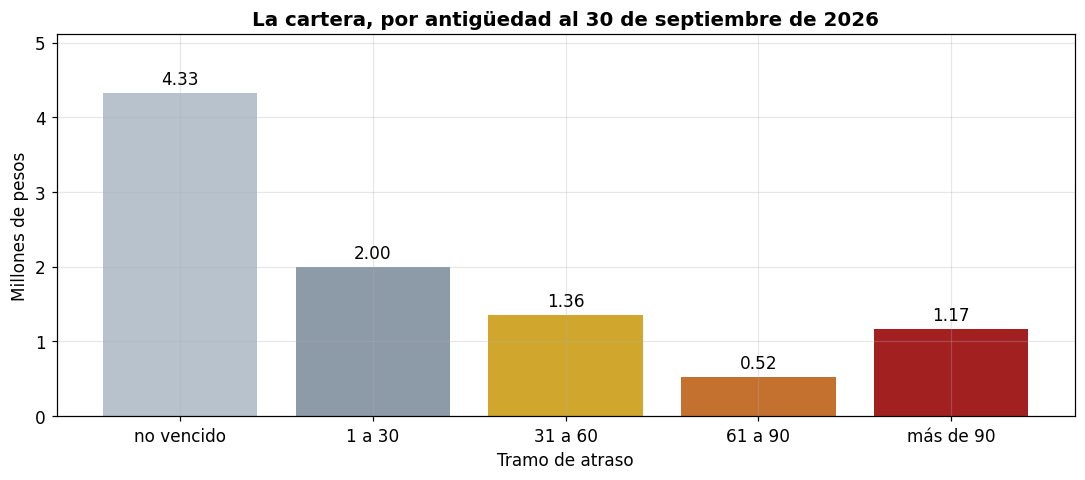

cartera abierta: MXN 9,387,302.00
a más de 90 días: MXN 1,172,555.42 (12.5% de la cartera)
vencido en total: MXN 5,057,052.16


In [25]:
# * ---- LA CARTERA QUE YA SE PASÓ DE LOS 90 DÍAS ---
# * La cartera se construye con lo que cada factura debe hoy: lo facturado, menos lo
# * cobrado, menos lo devuelto. La antigüedad se mide contra el corte del cierre.

cartera = pd.DataFrame({"saldo": abierto_despues})
cartera["cliente"] = facturas.set_index("folio")["cliente_codigo"].loc[cartera.index]
cartera["dias"] = dias_atraso.loc[cartera.index]
cartera["tramo"] = [tramo(d) for d in cartera["dias"]]
orden = ["no vencido", "1 a 30", "31 a 60", "61 a 90", "más de 90"]
por_tramo = cartera.groupby("tramo")["saldo"].sum().reindex(orden)
total_cartera = float(cartera["saldo"].sum())
vencido_90 = float(por_tramo["más de 90"])
parte_90 = vencido_90 / total_cartera

fig, ax = plt.subplots()
barras = ax.bar(por_tramo.index, por_tramo.values / 1e6,
                color=["#b8c2cc", "#8d9aa8", "#d0a72c", "#c4702f", "#a32020"])
ax.set_title("La cartera, por antigüedad al 30 de septiembre de 2026")
ax.set_xlabel("Tramo de atraso")
ax.set_ylabel("Millones de pesos")
ax.bar_label(barras, fmt="%.2f", padding=3)
ax.set_ylim(0, por_tramo.max() / 1e6 * 1.18)
plt.tight_layout()
plt.show()

print(f"cartera abierta: MXN {total_cartera:,.2f}")
print(f"a más de 90 días: MXN {vencido_90:,.2f} ({parte_90:.1%} de la cartera)")
print(f"vencido en total: MXN {total_cartera - float(por_tramo['no vencido']):,.2f}")

# * ---- PARTE 1 · DE DÓNDE SALE CADA PESO DE LA CARTERA ---
# abierto_despues → la serie de saldos por factura que quedó al final del paso 3, ya con el
#   pago mal aplicado reasignado. No se vuelve a calcular aquí: se usa la corregida.
# pd.DataFrame({"saldo": ...}) → convierte esa serie en tabla para poder pegarle columnas.
# .loc[cartera.index] → trae, para cada factura abierta, su cliente y sus días de atraso.
#   Los tres vienen de tablas distintas y se alinean por el folio, que es la llave.
# [tramo(d) for d in ...] → aplica la función de tramos del paso 3 a cada día de atraso.
#   Se usa la misma función, no una copia: si cambiara el criterio, cambia en un solo lugar.
# .reindex(orden) → fija el orden de los tramos, de lo más nuevo a lo más viejo. Sin esto,
#   pandas los ordenaría alfabéticamente y la gráfica perdería el sentido.
# ax.bar(...) → dibuja una barra por tramo, con el monto en millones para que las cifras
#   quepan en el eje. Los colores van del gris al rojo: el rojo es el dinero más viejo.
# ax.bar_label(barras, fmt="%.2f") → escribe encima de cada barra su valor, con dos
#   decimales. Sin esto la gráfica obliga a adivinar la altura.
# ? La gráfica es una sola idea: cuánto hay en cada tramo. Si el lector se lleva una cosa,
# ? es que la barra roja no es la más grande y aun así es la que hay que atender primero.

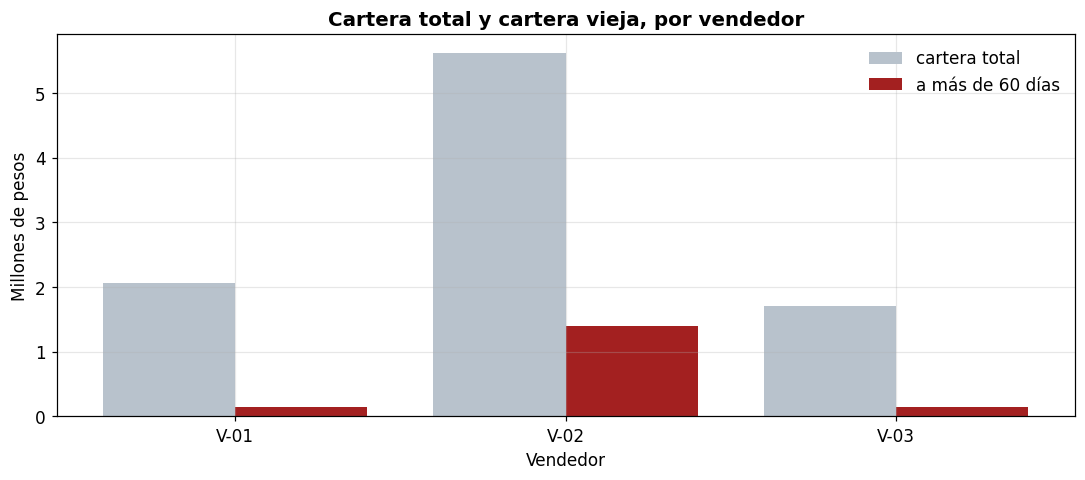

,cartera,vieja,parte
vendedor,,,
V-01,"2,064,124.57","148,938.56",7.2%
V-02,"5,622,265.55","1,399,247.14",24.9%
V-03,"1,700,911.88","147,878.43",8.7%


In [26]:
# * ---- QUIÉN CARGA CON LA COBRANZA VIEJA ---
# * La misma cartera, mirada por vendedor. No es un hallazgo distinto: es la misma deuda
# * repartida de otra manera, y sirve para saber a quién preguntarle.

vendedor_de = clientes.set_index("codigo")["vendedor"]
cartera["vendedor"] = cartera["cliente"].map(vendedor_de)
por_vendedor = cartera.groupby("vendedor").agg(cartera=("saldo", "sum"))
por_vendedor["vieja"] = (cartera[cartera["dias"] > 60]
                         .groupby("vendedor")["saldo"].sum())
por_vendedor["vieja"] = por_vendedor["vieja"].fillna(0)
por_vendedor["parte"] = por_vendedor["vieja"] / por_vendedor["cartera"]
peor_vendedor = por_vendedor["parte"].idxmax()
vieja_peor = float(por_vendedor.loc[peor_vendedor, "vieja"])

eje = por_vendedor.index
x = range(len(eje))
fig, ax = plt.subplots()
ax.bar([i - 0.2 for i in x], por_vendedor["cartera"] / 1e6, width=0.4,
       label="cartera total", color="#b8c2cc")
ax.bar([i + 0.2 for i in x], por_vendedor["vieja"] / 1e6, width=0.4,
       label="a más de 60 días", color="#a32020")
ax.set_xticks(list(x))
ax.set_xticklabels(eje)
ax.set_title("Cartera total y cartera vieja, por vendedor")
ax.set_xlabel("Vendedor")
ax.set_ylabel("Millones de pesos")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

tabla(por_vendedor, dinero=["cartera", "vieja"], parte=["parte"])

# * ---- PARTE 1 · LA MISMA DEUDA, POR VENDEDOR ---
# cartera["cliente"].map(vendedor_de) → a cada factura abierta le pega el vendedor de su
#   cliente, con el mismo diccionario que se usó para el RFC en el paso 3.
# groupby("vendedor").agg(cartera=("saldo", "sum")) → una fila por vendedor con la suma de
#   su cartera. agg permite nombrar la columna resultante en el mismo paso.
# cartera[cartera["dias"] > 60] → se queda solo con las facturas de más de dos meses. De
#   ahí, la suma por vendedor es su cartera vieja.
# .fillna(0) → un vendedor sin cartera vieja no aparece en el filtro; se rellena con cero
#   para que la comparación entre los tres no quede coja.
# [i - 0.2 for i in x] y [i + 0.2 for i in x] → corren media barra a cada lado para que las
#   dos barras de un mismo vendedor queden juntas y no encimadas.
# ? El número que importa no es cuánto tiene cada vendedor, sino qué proporción de lo suyo
# ? está viejo. Un vendedor con cartera chica y toda vencida es un problema distinto de uno
# ? con cartera grande y al día.
# ! Este hallazgo es el mismo dinero del hallazgo 1, no dinero adicional: si se suman los
# ! dos, se cuenta dos veces.

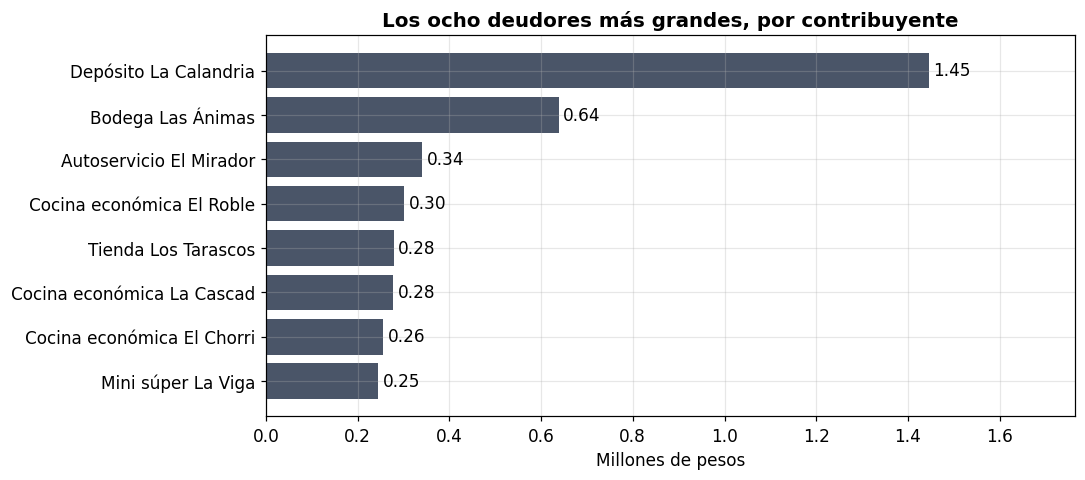

los ocho primeros deben MXN 3,782,320.59 (40.3% de la cartera)
los tres primeros deben MXN 2,424,162.96 (25.8%)
el mayor, con sus dos cuentas juntas: MXN 1,445,628.04 (15.4%)


In [27]:
# * ---- LA CONCENTRACIÓN: POCO DE MUCHOS O MUCHO DE POCOS ---
# * Qué pasa si el cliente más grande se atora. Se mide en la cartera, que es donde duele,
# * y se consolida por RFC para no volver a partir al mismo negocio en dos.

nombres = clientes.set_index("codigo")["nombre"]
rfc_de = clientes.set_index("codigo")["rfc"]
cartera["rfc"] = cartera["cliente"].map(rfc_de)
por_rfc = cartera.groupby("rfc")["saldo"].sum().sort_values(ascending=False)
mayor_rfc = float(por_rfc.iloc[0])
parte_mayor = mayor_rfc / total_cartera
top3_cartera = float(por_rfc.nlargest(3).sum())
parte_top3 = top3_cartera / total_cartera

nombre_por_rfc = cartera.groupby("rfc")["cliente"].first().map(nombres)
top8 = por_rfc.head(8)
etiquetas = [nombre_por_rfc[r][:26] for r in top8.index]
posiciones = list(range(len(top8)))
fig, ax = plt.subplots()
barras = ax.barh(posiciones, (top8.values / 1e6)[::-1], color="#4a5568")
ax.set_yticks(posiciones)
ax.set_yticklabels(etiquetas[::-1])
ax.set_title("Los ocho deudores más grandes, por contribuyente")
ax.set_xlabel("Millones de pesos")
ax.bar_label(barras, fmt="%.2f", padding=3)
ax.set_xlim(0, top8.max() / 1e6 * 1.22)
plt.tight_layout()
plt.show()

print(f"los ocho primeros deben MXN {top8.sum():,.2f} "
      f"({top8.sum() / total_cartera:.1%} de la cartera)")
print(f"los tres primeros deben MXN {top3_cartera:,.2f} ({parte_top3:.1%})")
print(f"el mayor, con sus dos cuentas juntas: MXN {mayor_rfc:,.2f} ({parte_mayor:.1%})")

# * ---- PARTE 1 · CONCENTRAR POR CONTRIBUYENTE, NO POR CUENTA ---
# cartera["rfc"] = cartera["cliente"].map(rfc_de) → pega a cada factura el RFC de su
#   cliente. Como el negocio con dos códigos comparte RFC, agrupar por RFC lo vuelve uno.
# groupby("rfc")["saldo"].sum().sort_values(ascending=False) → el ranking de deudores
#   reales, del que más debe al que menos.
# .iloc[0] → el primero de la lista. .nlargest(3) → los tres primeros.
# La división entre el total es la concentración: qué parte de toda la cartera depende de
#   unos cuantos.
# nombre_por_rfc = groupby("rfc")["cliente"].first().map(nombres) → un nombre por
#   contribuyente. Se toma el primero de sus cuentas, porque las dos son el mismo negocio.
# Las barras van horizontales porque los nombres son largos: en vertical no caben. Se
#   recortan a 26 caracteres para que el eje se lea.
# posiciones = list(range(len(top8))) → el eje vertical se numera de cero en adelante, y
#   los nombres se ponen aparte con set_yticklabels. Si se pasaran los nombres directo a
#   barh, matplotlib los trataría como categorías y dos nombres iguales —el negocio con dos
#   cuentas— se fusionarían en una sola barra, con el eje descuadrado.
# [::-1] → invierte el orden de la lista. En una barra horizontal, el primer elemento
#   queda abajo; invirtiendo, el que más debe queda arriba, que es donde se busca.
# ? Se muestran ocho y no tres a propósito: con ocho se ve la forma de la concentración.
# ? Con tres, el lector tendría que confiar en la cifra sin verla.

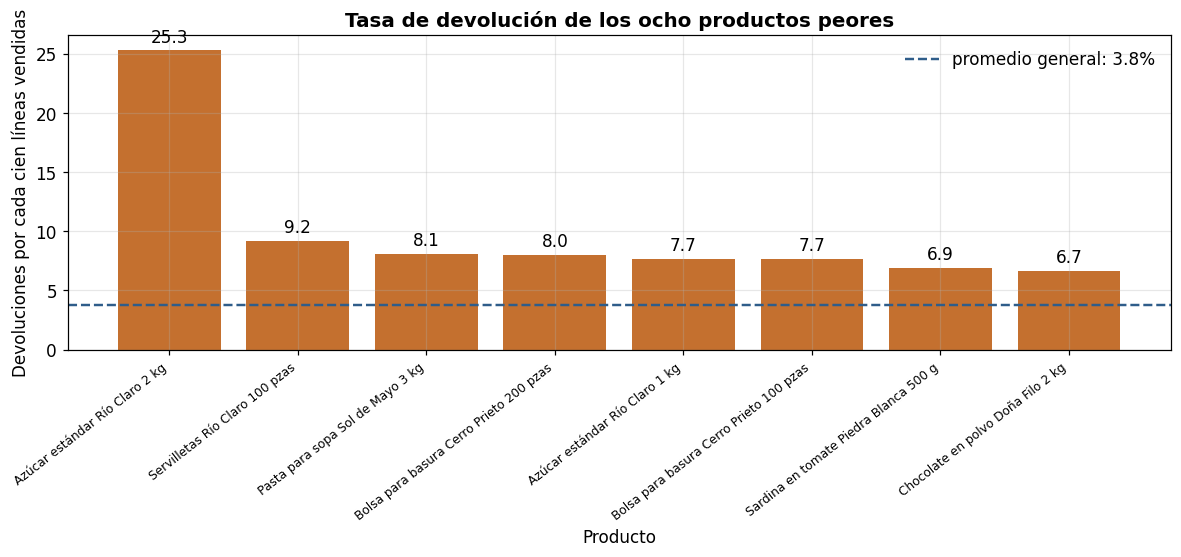

,nombre,notas,lineas,tasa,monto
producto_codigo,,,,,
P-0012,Azúcar estándar Río Claro 2 kg,23,91,25.3%,"71,495.49"
P-0111,Servilletas Río Claro 100 pzas,7,76,9.2%,"20,534.33"
P-0029,Pasta para sopa Sol de Mayo 3 kg,3,37,8.1%,"54,731.70"
P-0105,Bolsa para basura Cerro Prieto 200 pzas,2,25,8.0%,"24,814.38"


tasa general: 3.8% · total devuelto: MXN 1,450,604.47


In [28]:
# * ---- LAS DEVOLUCIONES SE CONCENTRAN EN POCOS PRODUCTOS ---
# * La tasa global de devolución es baja. El problema no es la tasa: es que un producto
# * esté muy por encima de ella. Se mide sobre las líneas vendidas, no sobre el dinero.

devoluciones = notas.groupby("producto_codigo").agg(
    notas=("folio_nota", "count"), monto=("importe_con_iva", "sum"))
devoluciones["lineas"] = ventas_limpias.groupby("producto_codigo").size()
devoluciones["tasa"] = devoluciones["notas"] / devoluciones["lineas"]
devoluciones["nombre"] = devoluciones.index.map(productos.set_index("codigo")["nombre"])
tasa_global = len(notas) / len(ventas_limpias)
con_volumen = devoluciones[devoluciones["lineas"] >= 20]
peor = con_volumen.sort_values("tasa", ascending=False).head(8)

posiciones = list(range(len(peor)))
fig, ax = plt.subplots(figsize=(11, 5.2))
barras = ax.bar(posiciones, peor["tasa"] * 100, color="#c4702f")
ax.axhline(tasa_global * 100, color="#2f5d8a", linestyle="--", linewidth=1.6,
           label=f"promedio general: {tasa_global:.1%}")
ax.set_xticks(posiciones)
ax.set_xticklabels(peor["nombre"], rotation=38, ha="right", fontsize=8)
ax.set_title("Tasa de devolución de los ocho productos peores")
ax.set_xlabel("Producto")
ax.set_ylabel("Devoluciones por cada cien líneas vendidas")
ax.bar_label(barras, fmt="%.1f", padding=3)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

tabla(con_volumen.sort_values("tasa", ascending=False).head(4)
      [["nombre", "notas", "lineas", "tasa", "monto"]],
      dinero=["monto"], parte=["tasa"])
print(f"tasa general: {tasa_global:.1%} · total devuelto: MXN {notas_total:,.2f}")

# * ---- PARTE 1 · LA TASA POR PRODUCTO ---
# notas.groupby("producto_codigo").agg(...) → por cada producto devuelto, cuántas notas y
#   cuánto dinero.
# ventas_limpias.groupby("producto_codigo").size() → cuántas líneas se vendieron de cada
#   producto. size() cuenta los renglones de cada grupo.
# tasa = notas / líneas → la proporción de devoluciones sobre lo vendido. Se mide por
#   líneas y no por dinero a propósito: una devolución de un producto caro no debe pesar
#   más que tres de uno barato.
# con_volumen → solo los productos con al menos veinte líneas vendidas. Sin ese piso, un
#   producto con una devolución sobre dos líneas saldría con tasa de 50 % y encabezaría la
#   lista. Una tasa alta sobre dos líneas no es un hallazgo: es un accidente.
# peor = ...head(8) → los ocho productos con la tasa más alta, entre los que tienen
#   volumen. El orden es por tasa, no por monto: primero se encuentra el patrón.
# ax.axhline(...) → una línea horizontal en la tasa general. Es la referencia que convierte
#   una barra alta en un hallazgo: sin ella, cualquier barra parece normal.
# posiciones = list(range(len(peor))) → el eje se numera y los nombres van aparte, igual que
#   en la gráfica de concentración. Aquí importa más: «Servilletas Río Claro 100 pzas» y
#   «Servilletas Río Claro 250 pzas» empiezan igual, y como categorías de texto matplotlib
#   las habría fundido en una sola barra, con dos valores encimados.
# plt.xticks(rotation=38, ha="right", fontsize=8) → los nombres son largos; se giran y se
#   achican para que quepan completos. No se recortan: un nombre cortado a la mitad es
#   peor que uno chico.
# ? Una tasa del 25 % no dice nada sola. Dice algo cuando el promedio es 3.8 %: tres de
# ? cada cuatro devoluciones de ese producto no son casualidad.

In [29]:
# * ---- CUATRO PRODUCTOS QUE SE VENDEN POR DEBAJO DE SU COSTO ---
# * No es una opinión sobre el precio: es la resta. Si el costo del catálogo es más alto
# * que el precio de venta, cada pieza que sale deja una pérdida.

margen_producto = con_costo.groupby("producto_codigo").agg(
    venta=("venta_sin_iva", "sum"), costo=("costo_total", "sum"))
margen_producto["margen"] = ((margen_producto["venta"] - margen_producto["costo"])
                             / margen_producto["venta"])
margen_producto["nombre"] = margen_producto.index.map(productos.set_index("codigo")["nombre"])
negativos = margen_producto[margen_producto["margen"] < 0].sort_values("margen")
perdida_directa = float((negativos["venta"] - negativos["costo"]).sum())
margen_que_falta = float((negativos["venta"] * margen
                          - (negativos["venta"] - negativos["costo"])).sum())
tabla(negativos[["nombre", "venta", "costo", "margen"]],
      dinero=["venta", "costo"], parte=["margen"])
print(f"pérdida directa en el año: MXN {abs(perdida_directa):,.2f}")
print(f"margen que no se ganó, contra el promedio del negocio: MXN {margen_que_falta:,.2f}")

# * ---- PARTE 1 · LA RESTA QUE CONVIERTE UNA SOSPECHA EN UN HALLAZGO ---
# groupby("producto_codigo").agg(venta=..., costo=...) → por producto, lo vendido sin IVA y
#   lo que costó. Las dos columnas ya existen desde el paso 4.
# margen = (venta − costo) / venta → un número negativo aquí significa que se vendió por
#   debajo del costo. No hay interpretación: es la resta.
# [margen < 0] → el filtro. sort_values("margen") los ordena del peor al menos malo.
# perdida_directa → la suma de lo que se pierde hoy, línea por línea.
# margen_que_falta → lo que habrían dejado si tuvieran el margen promedio del negocio. No
#   es una promesa de mejora: es el tamaño del hueco, para decidir si vale la pena revisar
#   el precio de esos cuatro.
# ? La diferencia entre las dos cifras importa: la primera es dinero que ya salió; la
# ? segunda es dinero que nunca entró. Se presentan separadas para no sumar peras con
# ! manzanas, y porque la primera es un hecho y la segunda es una oportunidad.

,nombre,venta,costo,margen
producto_codigo,,,,
P-0113,Servilletas Río Claro 500 pzas,"386,111.74","442,769.25",-14.7%
P-0013,Azúcar estándar Río Claro 5 kg,"271,232.09","293,391.78",-8.2%
P-0027,Pasta para sopa Sol de Mayo 500 g,"411,496.52","437,564.70",-6.3%
P-0061,Galletas Marías Río Claro 170 g,"234,654.79","247,539.20",-5.5%


pérdida directa en el año: MXN 117,769.79
margen que no se ganó, contra el promedio del negocio: MXN 266,913.71


In [30]:
# * ---- LOS CINCO HALLAZGOS, ORDENADOS POR MONTO ---
# * La tabla del final. El monto ordena; la columna «qué habilita» dice qué decisión abre
# * cada uno. Y una nota que va en el cierre: estos montos no se suman.

hallazgos = pd.DataFrame([
    {"#": 1,
     "Hallazgo": "Tres clientes concentran la cartera",
     "Monto en juego": top3_cartera,
     "Qué habilita": "Decidir si se pone un límite de crédito al mayor"},
    {"#": 2,
     "Hallazgo": f"El vendedor {peor_vendedor} carga con la cobranza vieja",
     "Monto en juego": vieja_peor,
     "Qué habilita": "Revisar su cartera antes que la de los otros dos"},
    {"#": 3,
     "Hallazgo": "Las devoluciones se concentran en un producto",
     "Monto en juego": float(notas_total),
     "Qué habilita": "Revisar por qué ese producto regresa tanto"},
    {"#": 4,
     "Hallazgo": "La cartera pasada de 90 días",
     "Monto en juego": vencido_90,
     "Qué habilita": "Cobrar o negociar esos saldos este mes"},
    {"#": 5,
     "Hallazgo": "Cuatro productos por debajo de su costo",
     "Monto en juego": abs(perdida_directa),
     "Qué habilita": "Revisar el precio de esos cuatro"},
])
hallazgos = hallazgos.sort_values("Monto en juego", ascending=False)
hallazgos["#"] = range(1, len(hallazgos) + 1)
hallazgos["Monto en juego"] = hallazgos["Monto en juego"].map(lambda x: f"{x:,.2f}")
print(hallazgos.to_string(index=False))

# * ---- PARTE 1 · POR QUÉ ESTA TABLA LLEVA UNA ADVERTENCIA ---
# Cada hallazgo se calcula en su celda y aquí solo se citan los números: ninguna cifra se
#   escribe a mano.
# .sort_values("Monto en juego") → ordena por el número, ANTES de darle formato de dinero.
#   Si se ordenara después, el monto sería texto y «117,769.79» quedaría arriba de
#   «1,399,247.14», porque la coma pesa menos que el uno. El formato va al final, para
#   mostrar; el orden va sobre el número, para no mentir.
# hallazgos["#"] = range(1, ...) → renumera después de ordenar, para que el número sea el
#   rango por monto y no el orden en que se escribieron las celdas.
# ! Los montos no se suman. Tres de estos cinco miran la misma cartera: la concentración por
# ! cliente, la cobranza vieja por vendedor y lo que pasó de 90 días. Sumarlos contaría el
# ! mismo dinero tres veces, y ese total falso es el error más común de un tablero.
# ? El orden por monto no es el orden de urgencia, y se dice en el cierre: lo más grande es
# ? la concentración, pero lo más urgente es el dinero que ya se pasó de los 90 días.

 #                                      Hallazgo Monto en juego                                     Qué habilita
 1           Tres clientes concentran la cartera   2,424,162.96 Decidir si se pone un límite de crédito al mayor
 2 Las devoluciones se concentran en un producto   1,450,604.47       Revisar por qué ese producto regresa tanto
 3  El vendedor V-02 carga con la cobranza vieja   1,399,247.14 Revisar su cartera antes que la de los otros dos
 4                  La cartera pasada de 90 días   1,172,555.42           Cobrar o negociar esos saldos este mes
 5       Cuatro productos por debajo de su costo     117,769.79                 Revisar el precio de esos cuatro


## Lo que este paso deja

- **Cinco hallazgos, cada uno con su cuenta.** Ninguno dice «hay oportunidad de mejora»:
  todos dicen cuánto dinero es y sobre qué dato se calculó.
- **Una sola gráfica por idea.** La antigüedad, la concentración, las devoluciones. Nada
  de tableros con veinte cuadros: lo que no cambia una decisión no entra.
- **Los montos no se suman.** Tres de los cinco miran la misma cartera. Sumarlos da un
  número grande y falso, y es el error más común de los tableros de «dinero en juego».
- **El orden por monto no es el orden de urgencia.** Lo más grande es la concentración;
  lo más urgente es lo que ya lleva más de 90 días sin cobrarse.

Cada uno de estos hallazgos depende de un supuesto del paso 4: la antigüedad, del corte;
la concentración, de haber consolidado por RFC; el margen, del costo del catálogo. El
**paso 6** dice qué de todo esto no se puede afirmar con estos datos y qué haría falta
para afirmarlo.

# Paso 6 · Lo que estos datos NO alcanzan a responder

Un análisis que no dice sus límites está pidiendo que le crean. Este paso es el que dice,
con el mismo cuidado que los hallazgos, **qué pregunta no se puede contestar** con estos
seis archivos, por qué, y qué haría falta para contestarla.

No es una lista de excusas: cada límite dice qué hallazgo del paso 5 deja más débil. Un
límite que no cambia ninguna conclusión no vale la pena escribirlo.

In [31]:
# * ---- LÍMITE 1 · LA VENTANA RECORTA LA CARTERA ---
# * Las facturas solo existen desde abril. Eso no es un detalle: significa que la deuda más
# * vieja no está en los datos. El número que se reportó es un piso, no un techo.

factura_mas_vieja = pd.to_datetime(facturas["fecha_emision"]).min()
dias_posibles = int((cierre.normalize() - factura_mas_vieja).days)
dias_observados = int(dias_atraso.loc[abierto_despues.index].max())
liquidadas = int((saldos_ok <= 0.005).sum())
print(f"la factura más vieja es del {factura_mas_vieja.date()}")
print(f"eso permite ver como máximo {dias_posibles} días de atraso")
print(f"la más atrasada que hay en la cartera: {dias_observados} días")
print(f"facturas liquidadas dentro de la ventana: {liquidadas} de {len(facturas)}")
print(f"seguían abiertas al corte: {len(abierto_despues)}")

# * ---- PARTE 1 · QUÉ SIGNIFICA QUE LA VENTANA EMPIECE EN ABRIL ---
# facturas["fecha_emision"] convertido a fecha y con .min() → el día más viejo que el
#   archivo conoce. Todo lo anterior no existe para el análisis.
# (cierre - factura_mas_vieja).days → cuántos días caben entre ese día y el corte. Es el
#   techo de antigüedad que los datos permiten: 182 días, medio año.
# dias_atraso.loc[abierto_despues.index].max() → la antigüedad real de la factura más vieja
#   que sigue sin pagarse. Es menor que el techo, y ahí está el problema.
# ! Este es el límite que más importa, y va en la dirección incómoda: si una factura de
# ! marzo no está en el archivo, el monto de más de 90 días que se reportó es un piso. La
# ! deuda vieja real es al menos esa; cuánto más, no se puede saber con estos datos.
# ? Lo contrario —un techo— sería cómodo y falso. Se dice tal como es: el número se queda
# ? corto, y quien decida con él debe saber que se queda corto.

la factura más vieja es del 2026-04-01
eso permite ver como máximo 182 días de atraso
la más atrasada que hay en la cartera: 149 días
facturas liquidadas dentro de la ventana: 340 de 514
seguían abiertas al corte: 262


In [32]:
# * ---- LÍMITE 2 · LAS VENTAS SIN FACTURA Y LOS CLIENTES QUE NO COMPRARON ---
# * Dos huecos que sí se pueden medir. No cambian el total, pero dejan preguntas abiertas.

sin_factura = ventas_limpias[ventas_limpias["folio"].str.startswith("NV")]
lineas_nv = int(len(sin_factura))
monto_nv = float(sin_factura["importe"].sum())
parte_nv = monto_nv / float(ventas_limpias["importe"].sum())
sin_compra = int(len(clientes) - ventas_limpias["cliente_codigo"].nunique())
print(f"líneas sin factura (nota de venta): {lineas_nv:,}")
print(f"su monto: MXN {monto_nv:,.2f} ({parte_nv:.1%} de la venta)")
print(f"clientes del catálogo que no compraron nada: {sin_compra} de {len(clientes)}")

# * ---- PARTE 1 · LO QUE ESTOS DOS HUECOS DEJAN SIN SABER ---
# .str.startswith("NV") → las líneas cuyo folio empieza con esas letras. Son documentos que
#   se entregaron y nunca se facturaron, así que no tienen contraparte en el archivo de
#   facturas ni en el de pagos.
# Su monto es venta, y por eso entra al cuadre: el total del dueño las incluye. Pero no se
#   puede saber si se cobraron, porque el cobro solo se registra contra una factura.
# sin_compra → la diferencia entre el catálogo y los clientes que aparecen al menos una vez
#   en las ventas. Son cuentas abiertas que no compraron en el año.
# ? Los dos son preguntas que sí tienen respuesta posible, no con estos archivos: con el
# ? reporte de cobranza de las notas de venta y con el motivo de alta de cada cuenta.

líneas sin factura (nota de venta): 174
su monto: MXN 1,283,804.82 (3.3% de la venta)
clientes del catálogo que no compraron nada: 23 de 180


In [33]:
# * ---- LA TABLA DE LÍMITES ---
# * Ocho preguntas que estos datos no pueden contestar. En cada una: por qué, qué haría
# * falta para contestarla y qué hallazgo del paso 5 queda más débil por eso.

limites = pd.DataFrame([
    {"#": 1,
     "Pregunta que no se puede contestar": "¿Cuánto de la cartera vieja se acaba cobrando?",
     "Por qué": "Hay seis meses de facturas y pagos, no más",
     "Qué haría falta": "Pagos de 24 meses o el reporte de castigos",
     "Qué queda débil": "El monto de más de 90 días: es un piso, no un techo"},
    {"#": 2,
     "Pregunta que no se puede contestar": "¿Cuánto capital hay detenido hoy en la bodega?",
     "Por qué": "El inventario es de un solo corte, de hace 92 días",
     "Qué haría falta": "Inventario mes a mes del año",
     "Qué queda débil": "No hay hallazgo: el capital detenido no se pudo medir"},
    {"#": 3,
     "Pregunta que no se puede contestar": "¿La empresa gana o pierde?",
     "Por qué": "No hay sueldos, renta ni fletes; solo compras de mercancía",
     "Qué haría falta": "Estado de resultados de los doce meses",
     "Qué queda débil": "El margen bruto no es utilidad y no debe leerse así"},
    {"#": 4,
     "Pregunta que no se puede contestar": "¿En cuál de las dos bodegas se pierde el margen?",
     "Por qué": "El reporte de ventas no trae la columna de almacén",
     "Qué haría falta": "La columna de almacén en el mismo reporte",
     "Qué queda débil": "El hallazgo del margen no se puede ubicar en una bodega"},
    {"#": 5,
     "Pregunta que no se puede contestar": "¿Por qué regresan los productos?",
     "Por qué": "El motivo es una etiqueta de cinco opciones, sin evidencia",
     "Qué haría falta": "Las notas con su causa documentada: foto, lote, transportista",
     "Qué queda débil": "El hallazgo de devoluciones dice dónde, no por qué"},
    {"#": 6,
     "Pregunta que no se puede contestar": "¿El margen se está deteriorando?",
     "Por qué": "Hay un solo costo, el de hoy, sin fecha",
     "Qué haría falta": "Costo por mes o por lote de compra",
     "Qué queda débil": "El margen es un promedio del año, no una tendencia"},
    {"#": 7,
     "Pregunta que no se puede contestar": "¿Las ventas caen por falta de producto?",
     "Por qué": "No hay pedidos no surtidos ni faltantes de la bodega",
     "Qué haría falta": "El reporte de pedidos pendientes por producto",
     "Qué queda débil": "No se puede separar la demanda del abasto"},
    {"#": 8,
     "Pregunta que no se puede contestar": "¿Este año es mejor que el anterior?",
     "Por qué": "Solo hay una ventana de doce meses",
     "Qué haría falta": "Los doce meses anteriores, con la misma estructura",
     "Qué queda débil": "La estacionalidad se ve una vez y sin comparación"},
])
print(limites.set_index("#").to_string())

# * ---- PARTE 1 · CÓMO ESTÁ ARMADA LA TABLA ---
# Cada renglón nombra la pregunta con la voz del dueño y no con la del analista: «¿la
#   empresa gana o pierde?» dice más que «falta el estado de resultados».
# La columna «Qué queda débil» es la que impide que esta tabla sea un trámite. Un límite
#   que no toca ningún hallazgo del paso 5 no se anota; y si lo toca, se dice cuál.
# ? Hay un renglón que no debilita un hallazgo, lo cancela: el del inventario. Ese hallazgo
# ? no se hizo y aquí se explica por qué, en lugar de esconderlo.

                 Pregunta que no se puede contestar                                                     Por qué                                                Qué haría falta                                          Qué queda débil
#                                                                                                                                                                                                                                      
1    ¿Cuánto de la cartera vieja se acaba cobrando?                  Hay seis meses de facturas y pagos, no más                     Pagos de 24 meses o el reporte de castigos      El monto de más de 90 días: es un piso, no un techo
2    ¿Cuánto capital hay detenido hoy en la bodega?          El inventario es de un solo corte, de hace 92 días                                   Inventario mes a mes del año    No hay hallazgo: el capital detenido no se pudo medir
3                        ¿La empresa gana o pierde?  No hay sueldos, ren

In [34]:
# * ---- LÍMITE 3 · LA DIFERENCIA ENTRE VENDEDORES NO SE PUEDE ATRIBUIR ---
# * El hallazgo dice que la cartera de un vendedor está más vieja que la de los otros. Eso es
# * un hecho del dato. Decir que el vendedor lo causa es otra cosa, y no está sostenido.

plazo = clientes.groupby("vendedor")["credito_dias"].mean()
mayoreo = clientes.groupby("vendedor")["tipo"].apply(lambda s: (s == "Mayoreo").mean())
comparacion = por_vendedor[["cartera", "vieja", "parte"]].copy()
comparacion["plazo (días)"] = plazo.round(1)
comparacion["clientes de mayoreo"] = mayoreo
tabla(comparacion, dinero=["cartera", "vieja"], parte=["parte", "clientes de mayoreo"])
print("con estos datos no se puede separar el vendedor de los clientes que le tocaron")

# * ---- PARTE 1 · POR QUÉ NO ES CAUSAL ---
# groupby("vendedor")["credito_dias"].mean() → el plazo promedio que se le autorizó a los
#   clientes de cada vendedor. Si los plazos fueran muy distintos, la diferencia de cartera
#   vieja se explicaría por las condiciones y no por el vendedor.
# (s == "Mayoreo").mean() → la proporción de clientes de mayoreo. Un vendedor con más
#   mayoreo cobra más tarde por la naturaleza de su cartera, no por cómo cobra.
# Los dos números salen casi parejos entre los tres, y aun así no alcanza: la asignación de
#   clientes no fue al azar. Un vendedor puede haber recibido las cuentas más difíciles.
# ! Para afirmar que el vendedor causa la morosidad haría falta un diseño: comparar clientes
# ! parecidos asignados al azar, o un corte donde el mismo vendedor cambie de cartera. Con
# ! una foto de los tres, lo único defendible es la descripción y la pregunta.
# ? El hallazgo se queda como está —«la cartera de este vendedor es la más vieja»— porque
# ? eso sí es un hecho. Lo que se quita es la conclusión de que él es la causa.

,cartera,vieja,parte,plazo (días),clientes de mayoreo
vendedor,,,,,
V-01,"2,064,124.57","148,938.56",7.2%,43.500000,41.9%
V-02,"5,622,265.55","1,399,247.14",24.9%,42.500000,55.2%
V-03,"1,700,911.88","147,878.43",8.7%,37.100000,37.3%


con estos datos no se puede separar el vendedor de los clientes que le tocaron


## Lo que este paso deja

- **Ocho límites, cada uno con su efecto sobre lo que se dijo.** El más importante va en
  la dirección incómoda: el monto de más de 90 días se queda corto.
- **Un hallazgo que no se hizo, y por qué.** El capital detenido en inventario no se pudo
  medir con un corte de hace 92 días. Se dice en lugar de rellenarlo.
- **Ninguna afirmación de causalidad.** La diferencia entre vendedores es un hecho del
  dato; decir que el vendedor la causa no está sostenido por este diseño. La forma de
  sostenerlo también se dice: comparar clientes parecidos, no una foto de tres.
- **Un límite no es una disculpa.** Es lo que separa un análisis que se puede usar de uno
  que solo se puede creer. Lo que sigue —**el paso 7**— es cómo se comprueba si la
  decisión sirvió: qué se mide, con qué dato y en cuánto tiempo.

Con esto el cuaderno ya dice lo que sabe y lo que no. Falta la parte que casi nunca se
escribe: cómo sabremos, dentro de tres meses, si la decisión fue la correcta.

# Paso 7 · Cómo sabremos si funcionó

Un hallazgo que no se puede volver a medir es una anécdota. Este paso deja, para cada uno
de los cinco, **qué se mide, con qué dato, contra qué número de hoy y en cuánto tiempo**.

Y deja una columna que casi nunca se escribe: qué haría tramposa la medición. Sin eso, el
número de dentro de tres meses se puede leer como una victoria aunque no lo sea.

In [35]:
# * ---- LA LÍNEA BASE: LOS NÚMEROS DE HOY ---
# * Para saber si algo cambió hay que dejarlo anotado antes de tocar nada. Estos son los
# * cinco números contra los que se va a comparar, con el mismo corte del 30 de septiembre.

tasa_peor = float(peor.iloc[0]["tasa"])
nombre_peor = str(peor.iloc[0]["nombre"])
margen_peor = float(margen_producto["margen"].min())
parte_v02 = float(por_vendedor.loc[peor_vendedor, "parte"])

linea_base = pd.DataFrame([
    {"#": 1, "Indicador": "Parte de la cartera en los tres mayores deudores",
     "Hoy": f"{parte_top3:.1%}", "Monto del hallazgo": top3_cartera},
    {"#": 2, "Indicador": f"Tasa de devolución de {nombre_peor}",
     "Hoy": f"{tasa_peor:.1%}", "Monto del hallazgo": float(notas_total)},
    {"#": 3, "Indicador": f"Parte de la cartera de {peor_vendedor} con más de 60 días",
     "Hoy": f"{parte_v02:.1%}", "Monto del hallazgo": vieja_peor},
    {"#": 4, "Indicador": "Parte de la cartera con más de 90 días",
     "Hoy": f"{parte_90:.1%}", "Monto del hallazgo": vencido_90},
    {"#": 5, "Indicador": "Margen del peor producto de los cuatro",
     "Hoy": f"{margen_peor:.1%}", "Monto del hallazgo": abs(perdida_directa)},
])
tabla(linea_base, dinero=["Monto del hallazgo"])

# * ---- PARTE 1 · LO QUE SE ANOTA ANTES DE EMPEZAR ---
# tasa_peor y nombre_peor → el producto con la tasa de devolución más alta entre los que
#   tienen volumen. Se sacan de la tabla del paso 5, no se escriben a mano.
# margen_peor → el margen más negativo de los cuatro productos que se venden bajo costo.
# parte_v02 → la proporción de la cartera vieja del vendedor que salió peor. Se busca por
#   su nombre, así que si el peor vendedor cambia, la tabla cambia con él.
# ? Los cinco indicadores son proporciones, no montos, salvo el último. Una proporción se
# ? puede comparar aunque el negocio crezca; un monto no. Esa decisión se explica en la
# ? celda siguiente, y es la más importante de todo el paso.

,#,Indicador,Hoy,Monto del hallazgo
0,1,Parte de la cartera en los tres mayores deudores,25.8%,"2,424,162.96"
1,2,Tasa de devolución de Azúcar estándar Río Claro 2 kg,25.3%,"1,450,604.47"
2,3,Parte de la cartera de V-02 con más de 60 días,24.9%,"1,399,247.14"
3,4,Parte de la cartera con más de 90 días,12.5%,"1,172,555.42"
4,5,Margen del peor producto de los cuatro,-14.7%,"117,769.79"


In [36]:
# * ---- LA TABLA DE MEDICIÓN ---
# * Cada hallazgo con la decisión que habilita, el indicador que se va a seguir, con qué
# * archivo se calcula, cuándo se revisa y qué la haría tramposa.

medicion = pd.DataFrame([
    {"#": 1,
     "Decisión que habilita": "Poner o no un límite de crédito al mayor deudor",
     "Qué se mide": "Parte de la cartera en los tres mayores",
     "Con qué dato": "Facturas, pagos y notas del trimestre",
     "Cuándo": "Al cierre de cada trimestre",
     "Qué la haría tramposa": "Si la cartera total baja, la parte sube sin que el riesgo suba"},
    {"#": 2,
     "Decisión que habilita": "Revisar por qué ese producto regresa tanto",
     "Qué se mide": "Tasa de devolución del producto, por motivo",
     "Con qué dato": "Notas de crédito del mes, con su motivo",
     "Cuándo": "Cada mes, tres meses seguidos",
     "Qué la haría tramposa": "Un lote dañado puntual mueve la tasa sin que el problema sea el producto"},
    {"#": 3,
     "Decisión que habilita": "Revisar su cartera antes que la de los otros dos",
     "Qué se mide": "Parte de su cartera con más de 60 días",
     "Con qué dato": "Facturas y pagos del mes, por vendedor",
     "Cuándo": "Cada mes",
     "Qué la haría tramposa": "Si le entran cuentas nuevas o grandes, la proporción se mueve por mezcla"},
    {"#": 4,
     "Decisión que habilita": "Cobrar o negociar esos saldos este mes",
     "Qué se mide": "Parte de la cartera con más de 90 días",
     "Con qué dato": "Facturas y pagos del mes",
     "Cuándo": "Cada mes",
     "Qué la haría tramposa": "El monto sube solo porque la ventana de facturas se alarga; la proporción no"},
    {"#": 5,
     "Decisión que habilita": "Revisar el precio de esos cuatro productos",
     "Qué se mide": "Margen de esos cuatro productos, uno por uno",
     "Con qué dato": "Ventas del mes y el costo vigente del catálogo",
     "Cuándo": "Un mes después de cambiar el precio",
     "Qué la haría tramposa": "Si el costo se mueve, el margen cambia aunque el precio no"},
])
print(medicion.set_index("#").to_string())

# * ---- PARTE 1 · POR QUÉ CADA RENGLÓN TIENE ESAS CINCO COLUMNAS ---
# «Decisión que habilita» → lo que se va a hacer con el hallazgo. Sin una decisión, el
#   indicador no sirve para nada: se mide por medir.
# «Qué se mide» → el indicador, en una frase. Si no cabe en una frase, no es un indicador.
# «Con qué dato» → el archivo del que sale. Si no se sabe de dónde sale, no se puede volver
#   a medir, y entonces no es una medición: es un recuerdo.
# «Cuándo» → la fecha de la siguiente lectura. Un indicador sin fecha se revisa nunca.
# «Qué la haría tramposa» → la forma más fácil de leerlo mal. Es la columna que convierte
#   esta tabla en algo distinto de una lista de buenos deseos.
# ? Ninguna fila dice cuánto va a mejorar. Ese número no se puede prometer: depende de las
# ? decisiones que tome el dueño y de cosas que no están en estos archivos.

                              Decisión que habilita                                   Qué se mide                                    Con qué dato                               Cuándo                                                         Qué la haría tramposa
#                                                                                                                                                                                                                                                                   
1   Poner o no un límite de crédito al mayor deudor       Parte de la cartera en los tres mayores           Facturas, pagos y notas del trimestre          Al cierre de cada trimestre                Si la cartera total baja, la parte sube sin que el riesgo suba
2        Revisar por qué ese producto regresa tanto   Tasa de devolución del producto, por motivo         Notas de crédito del mes, con su motivo        Cada mes, tres meses seguidos      Un lote dañado puntual mueve 

In [37]:
# * ---- LA TRAMPA DE MEDIR MONTOS EN UNA VENTANA QUE CRECE ---
# * El indicador 4 se mide en proporción y no en pesos por una razón concreta, y se puede
# * mostrar: el monto de más de 90 días sube solo con que pasen los meses.

dias_elegibles = max(0, dias_posibles - 90)
meses_elegibles = dias_elegibles / 30.44
meses_ventana = round(dias_posibles / 30.44)
print(f"la ventana de facturas tiene {meses_ventana} meses")
print(f"de esos, solo {meses_elegibles:.1f} pueden tener facturas de más de 90 días")
print(f"o sea, {meses_elegibles / meses_ventana:.0%} de la ventana")
print(f"en tres meses la ventana tendrá {meses_ventana + 3} meses y "
      f"{meses_elegibles + 3:.1f} elegibles: el monto podría subir sin que nada empeore")

# * ---- PARTE 1 · POR QUÉ EL PORCENTAJE SÍ ES COMPARABLE ---
# dias_posibles - 90 → de los 182 días de historia, cuántos alcanzan a tener facturas con más
#   de 90 días de atraso. Solo los primeros 92 días, o sea unos tres meses.
# / 30.44 → el promedio de días de un mes. Sirve para pasar días a meses sin calendario.
# meses_ventana = dias_posibles / 30.44 → cuántos meses tiene la ventana de FACTURAS, que
#   son seis, no los doce de las ventas. Es la ventana que importa aquí, porque la cartera
#   se construye con facturas.
# / meses_ventana → qué parte de la ventana puede siquiera aportar deuda vieja.
# Dentro de tres meses, el archivo tendrá nueve meses de facturas y seis podrán aportar
#   deuda vieja. El mismo negocio, sin empeorar, mostraría un monto mayor.
# ! Por eso el indicador es la proporción. Comparar montos entre cortes con ventanas de
# ! distinto tamaño es comparar dos cosas distintas y llamarlo mejora o retroceso.
# ? La proporción tiene su propia trampa —si el negocio crece, la proporción baja sin que se
# ? haya cobrado mejor— y por eso la columna de la trampa lo dice en cada renglón.

la ventana de facturas tiene 6 meses
de esos, solo 3.0 pueden tener facturas de más de 90 días
o sea, 50% de la ventana
en tres meses la ventana tendrá 9 meses y 6.0 elegibles: el monto podría subir sin que nada empeore


## Lo que este paso deja

- **Cinco indicadores con línea base, fuente y fecha.** El número de hoy queda anotado
  antes de tocar nada, y con el mismo corte del 30 de septiembre.
- **La columna que importa es la última.** Qué haría tramposa la medición. Sin ella, el
  número de dentro de tres meses se puede leer como una victoria aunque no lo sea.
- **Se mide en proporción, no en pesos.** La ventana de facturas crece cada mes, así que
  el monto de la cartera vieja sube solo. Compararlo entre cortes sería comparar dos cosas
  distintas.
- **Ningún indicador promete una mejora.** No hay meta de resultado ni compromiso de
  ahorro: hay una forma de comprobar, dentro de tres meses, si la decisión sirvió.

Con esto el cuaderno está completo: datos limpios, defectos con su efecto, supuestos
medidos, hallazgos ordenados por dinero, límites escritos y una forma de comprobar.

## Alcance y limitaciones

Este trabajo es analítica de datos aplicada a decisiones comerciales y de finanzas
corporativas. No constituye asesoría fiscal, contable, legal ni de inversión, ni un
dictamen o auditoría. Las cifras se derivan de la información proporcionada por el
cliente y de los supuestos declarados en este documento; su exactitud depende de la
calidad de esa información. Los resultados no están garantizados: dependen de los
datos de origen y de las decisiones que el cliente tome. Este entregable es un insumo
para decidir, no una recomendación de inversión ni una opinión fiscal.

---

**Los datos de este cuaderno son inventados.** La empresa, sus clientes, sus productos y
todas las cifras los construí yo para mostrar el método completo, con sus defectos y sus
límites, sin usar información de nadie. El código que produce los datos está en
`generar_datos.py` y se reconstruye con una semilla fija.